# 타이타닉 생존자 예측 

- Kaggle 데이터 분석 입문 튜토리얼 **Titanic - Machine Learning from Disaster**

<img src='https://mintaewon.github.io/images/Titanic/titanic.jpg'>

## 배경지식

RMS 타이타닉호는 1912년 4월 10일 영국 사우샘프턴을 떠나 미국 뉴욕으로 향하던 첫 항해 중, 4월 15일 빙산과 충돌하여 침몰했습니다.
이 사고로 1,514명이 사망했습니다. 구명보트가 부족했고, **"여성과 어린이 먼저"** 원칙이 있었다고 알려져 있습니다.
이 배경지식이 데이터 분석에서 세울 **가설**의 출발점이 됩니다.

## 목표

생존 여부가 포함된 탑승객 학습 데이터(train)를 분석하고, 그 정보로 기계학습 모델을 만들어
테스트 데이터(test) 탑승객의 생존 여부(0/1)를 예측합니다. Kaggle 채점 지표는 **정확도(Accuracy)** 입니다.


##  분석 흐름 (목차)

| 단계 | 내용 |
|---|---|
| 1 | 환경 준비와 데이터 불러오기 |
| 2 | 데이터 첫인상 — 크기, 열 종류, 기초 통계 |
| 3 | 결측값 진단 — 얼마나, 그리고 **왜** 비었나 |
| 4 | 목표변수(Survived)와 기준선 |
| 5 | 범주형 변수와 생존 — 성별, 등급, 항구, 가족 수 |
| 6 | 수치형 변수와 생존 — 나이, 요금 |
| 7 | 이름에서 호칭(Title) 뽑기 |
| 8 | 결측값 채우기 |
| 9 | 새 특성 만들기 — 가족, 객실, 티켓 |
| 10 | 특성 간 상관관계 |
| 11 | 모델링 — 왜 LinearRegression이 아닌가, 모델 6종 비교 |
| 12 | 특성을 하나씩 추가하며 효과 확인 |
| 13 | 모델 해석과 오답 분석 |
| 14 | 하이퍼파라미터 조정과 최종 제출 |
| 15 | 정리 |
| 부록 | pandas 문자열 함수와 정규표현식 (원본 내용 보존·수정) |

각 분석은 **가설 →  확인 →  결론** 순서로 진행합니다.

---
# 1. 환경 준비와 데이터 불러오기

### 1-1 패키지 설치

필요한 패키지가 없으면 설치합니다(이미 있으면 건너뜀). 지금 노트북을 실행하는 파이썬에 설치하므로
"설치했는데 `ModuleNotFoundError`" 문제가 생기지 않습니다. 처음 한 번만 인터넷이 필요합니다.

In [1]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version

REQUIRED = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}
missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print('설치합니다:', missing)
    if importlib.util.find_spec('pip') is None:
        subprocess.check_call([sys.executable, '-m', 'ensurepip', '--upgrade'])
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
                           '--disable-pip-version-check', *missing])
    print('설치 완료! 다음 셀에서 오류가 나면 Kernel(런타임) → Restart 후 다시 실행하세요.')
else:
    print('필요한 패키지가 모두 설치되어 있습니다.')
for module, pip_name in REQUIRED.items():
    print(f'  {pip_name:13s} {version(pip_name)}')

필요한 패키지가 모두 설치되어 있습니다.
  numpy         2.5.3
  pandas        3.0.6
  matplotlib    3.11.2
  seaborn       0.13.2
  scikit-learn  1.9.1


### 1-2 데이터 불러오기

원본은 Colab에서 Kaggle API(`kaggle.json`)로 내려받았습니다. 그 방법은 그대로 쓸 수 있습니다.

```text
# (선택) 원본 방식 — Colab + Kaggle API
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p ~/.kaggle && cp /content/drive/MyDrive/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c titanic && unzip titanic.zip -d titanic
```

아래 셀은 **어디서 실행해도** 동작하게 만들었습니다.
1. 노트북 옆 `titanic/` 폴더 → Colab 드라이브 `/content/drive/MyDrive/titanic/` → `/content/` 순서로 `train.csv`, `test.csv`를 찾습니다.
2. 없으면 공개 저장소에서 Kaggle과 같은 파일을 내려받아 `titanic/` 폴더에 저장합니다(다음부터는 인터넷 불필요).

In [2]:
from pathlib import Path
import urllib.request
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
SEED = 42

CANDIDATES = [Path('titanic'), Path('/content/drive/MyDrive/titanic'), Path('/content')]
MIRROR = 'https://raw.githubusercontent.com/agconti/kaggle-titanic/master/data/'

for DATA_DIR in CANDIDATES:
    if (DATA_DIR / 'train.csv').exists() and (DATA_DIR / 'test.csv').exists():
        break
else:
    DATA_DIR = Path('titanic')
    DATA_DIR.mkdir(exist_ok=True)
    for name in ['train.csv', 'test.csv']:
        urllib.request.urlretrieve(MIRROR + name, DATA_DIR / name)
    print('데이터를 내려받았습니다 →', DATA_DIR.resolve())

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
raw_train, raw_test = train.copy(), test.copy()      # 원본 보관 (나중에 비교용)
print('데이터 위치:', DATA_DIR.resolve())
print('train', train.shape, '| test', test.shape)

데이터를 내려받았습니다 → G:\내 드라이브\강의자료\국방\2026 국방경진대회 준비\titanic
데이터 위치: G:\내 드라이브\강의자료\국방\2026 국방경진대회 준비\titanic
train (891, 12) | test (418, 11)


---
# 2. 데이터 첫인상

## Data Dictionary — 열마다 "종류"와 "예상"까지 적어 둡니다

| 열 | 뜻 | 종류 | 분석 전 예상 |
|---|---|---|---|
| `PassengerId` | 승객 번호 | 식별자 | 생존과 무관 → 모델에서 제외, 제출 파일에만 사용 |
| `Survived` | 생존 여부 (0 = 사망, 1 = 생존) | **목표변수** | train에만 있음 |
| `Pclass` | 티켓 등급 (1 = 1등석, 2 = 2등석, 3 = 3등석) | 순서 있는 범주 | 1등석일수록 구명보트에 가까워 생존↑? |
| `Name` | 이름 | 글자 | 그대로는 못 쓰지만 **호칭(Mr, Mrs, Miss…)** 에 성별·나이 정보 |
| `Sex` | 성별 | 범주 | "여성 먼저" → 여성 생존↑? |
| `Age` | 나이 | 수치 | "어린이 먼저" → 어린이 생존↑? |
| `SibSp` | 함께 탄 형제자매·배우자 수 | 수치(개수) | 가족이 있으면 도움? 너무 많으면 불리? |
| `Parch` | 함께 탄 부모·자녀 수 | 수치(개수) | 위와 같음 |
| `Ticket` | 티켓 번호 | 글자 | 같은 티켓 = 같은 일행 |
| `Fare` | 요금 | 수치 | 비싼 요금 = 높은 등급 = 생존↑? |
| `Cabin` | 객실 번호 | 글자 | 대부분 비어 있음. 기록이 있다는 것 자체가 정보? |
| `Embarked` | 탑승 항구 (S = Southampton, C = Cherbourg, Q = Queenstown) | 범주 | 직접 원인보다는 다른 변수와 얽혀 있을 것 |

In [3]:
display(train.head())
display(train.tail(3))
display(test.head(3))
print(train.shape, test.shape, '→ test에는 Survived 열이 없습니다:', 'Survived' not in test.columns)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q


(891, 12) (418, 11) → test에는 Survived 열이 없습니다: True


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


 **`info()` 읽기** — 891행 중 `Age`는 714개, `Cabin`은 204개, `Embarked`는 889개만 값이 있습니다.
`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`는 글자(`object`)라서 모델에 넣기 전에 숫자로 바꿔야 합니다.

In [5]:
display(train.describe().round(2))
display(train.describe(include='object'))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


 **기초 통계 읽기**

| 열 | 관찰 | 의미 |
|---|---|---|
| `Survived` | 평균 0.38 | 0/1 열의 평균 = 생존 비율 **38.4%** |
| `Pclass` | 중앙값 3 | 승객의 절반 이상이 3등석 |
| `Age` | 평균 29.7, 중앙값 28, 최소 0.42(5개월 아기), 최대 80 | 젊은 승객이 많음 |
| `SibSp`, `Parch` | 중앙값 0, 최대 8·6 | 대부분 혼자, 일부 대가족 |
| `Fare` | **평균 32.2 > 중앙값 14.5**, 최대 512 | 소수의 아주 비싼 요금이 평균을 끌어올림 → 오른쪽으로 긴 꼬리 (6장) |
| `Name` | 고유값 891개 | 모두 다름 → 그대로는 쓸모없음, 호칭을 뽑아야 함 (7장) |
| `Ticket` | 고유값 681개 | 같은 티켓을 쓴 승객이 있음 → 일행 (9장) |
| `Cabin` | 고유값 147개, 값 있는 행 204개 | 대부분 비어 있음 (3장) |

---
# 3. 결측값 진단 — 얼마나, 그리고 왜 비었나

결측값은 "개수"만 세고 끝내면 안 됩니다. 세 가지를 확인합니다.
1. **얼마나** 비었나 (train과 test 모두)
2. **어떻게** 채울까, 아니면 버릴까
3. **비어 있다는 사실 자체가** 생존과 관계있나

,train 결측수,train 결측률,test 결측수,test 결측률
Age,177,0.199,86.0,0.206
Cabin,687,0.771,327.0,0.782
Embarked,2,0.002,0.0,0.000
Fare,0,0.000,1.0,0.002


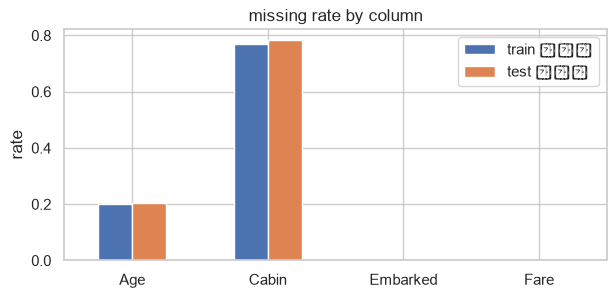

In [6]:
missing = pd.DataFrame({
    'train 결측수': train.isna().sum(), 'train 결측률': train.isna().mean().round(3),
    'test 결측수': test.isna().sum(), 'test 결측률': test.isna().mean().round(3),
})
missing = missing[(missing['train 결측수'] > 0) | (missing['test 결측수'] > 0)]
display(missing)

missing[['train 결측률', 'test 결측률']].plot.bar(figsize=(7, 3), rot=0)
plt.title('missing rate by column'); plt.ylabel('rate'); plt.show()

| 열 | 결측 | 처리 방향 |
|---|---|---|
| `Age` | train 177개(19.9%), test 86개(20.6%) | 중요한 열이라 **채워서 사용**. 단순 평균이 아니라 호칭별 중앙값으로 (8장) |
| `Cabin` | train 687개(77.1%) | 값 자체는 대부분 없지만 **"기록이 있는가"를 새 특성으로** (9장) |
| `Embarked` | train 2개 | 최빈값으로 채움 (8장) |
| `Fare` | test 1개 | 같은 등급의 train 중앙값으로 채움 (8장) |

 **가설: "비어 있다"는 것 자체가 정보일 수 있다.** 사망자의 나이나 객실은 기록이 남지 않았을 가능성이 있습니다.

In [7]:
rows = []
for col in ['Age', 'Cabin']:
    is_missing = train[col].isna()
    rows.append({'열': col,
                 '비어 있는 승객 수': int(is_missing.sum()),
                 '비어 있을 때 생존률': train.loc[is_missing, 'Survived'].mean(),
                 '값이 있을 때 생존률': train.loc[~is_missing, 'Survived'].mean()})
display(pd.DataFrame(rows).round(3))

,열,비어 있는 승객 수,비어 있을 때 생존률,값이 있을 때 생존률
0,Age,177,0.294,0.406
1,Cabin,687,0.300,0.667


 **결론**
- `Age`가 비어 있는 승객의 생존률은 **29%**, 값이 있는 승객은 **41%**입니다.
- `Cabin` 기록이 있는 승객은 **67%**가 생존했고, 없는 승객은 **30%**만 생존했습니다. 차이가 아주 큽니다.
- 객실 기록은 주로 1등석 승객에게 남아 있습니다(6장에서 확인). 따라서 "객실 기록 있음"은 **높은 등급의 신호**이기도 합니다.

>  원본은 "Cabin은 결측이 많아 사용 불가"로 결론 냈지만, **값은 못 써도 "있다/없다"는 강력한 특성**이 됩니다.

---
# 4. 목표변수(Survived)와 기준선

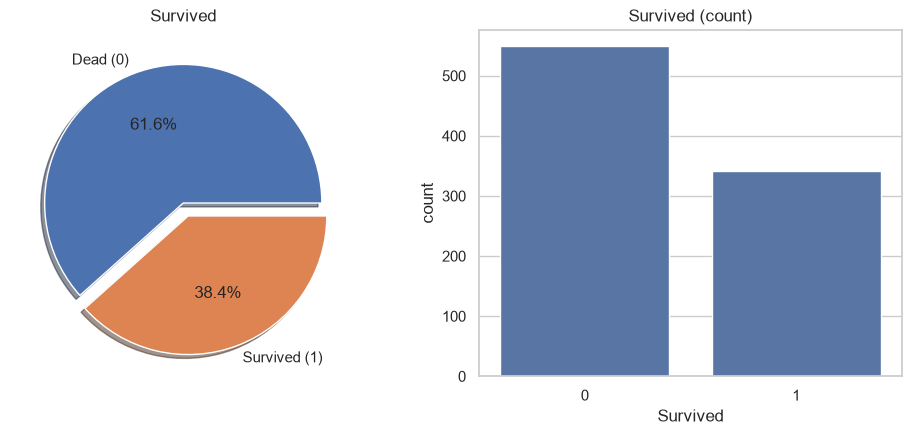

Survived
사망    549
생존    342
Name: count, dtype: int64

기준선: 모두 '사망'이라고 찍으면 정확도 = 0.616


In [8]:
f, ax = plt.subplots(1, 2, figsize=(12, 4.5))
train['Survived'].value_counts().plot.pie(explode=[0, 0.1], autopct='%1.1f%%', ax=ax[0], shadow=True,
                                          labels=['Dead (0)', 'Survived (1)'])
ax[0].set_title('Survived'); ax[0].set_ylabel('')
sns.countplot(x='Survived', data=train, ax=ax[1])
ax[1].set_title('Survived (count)')
plt.show()

print(train['Survived'].value_counts().rename({0: '사망', 1: '생존'}))
print(f"\n기준선: 모두 '사망'이라고 찍으면 정확도 = {1 - train['Survived'].mean():.3f}")

 **기준선(baseline)** — 아무것도 배우지 않고 가장 흔한 답(사망)만 쓰는 답안의 점수입니다.
**정확도 61.6%** 가 나옵니다. 앞으로 만드는 모든 모델은 이 숫자와 비교해야 합니다.
"정확도 70%"는 좋아 보이지만 기준선보다 8%p 높을 뿐입니다.

---
# 5. 범주형 변수와 생존

원본의 `bar_chart` 함수(생존자·사망자 수를 누적 막대로)는 그대로 쓰고, **비율**을 함께 보는 함수를 추가합니다.
인원이 다른 그룹을 비교할 때는 **개수가 아니라 비율**을 봐야 하기 때문입니다.
(예: 3등석 생존자 119명이 1등석 136명과 비슷해 보여도, 3등석은 491명 중 119명이라 비율은 훨씬 낮습니다.)

In [9]:
def bar_chart(feature, data=None):
    """원본 함수: 생존자/사망자 수를 범주별 누적 막대로 그립니다."""
    data = train if data is None else data
    survived = data[data['Survived'] == 1][feature].value_counts()
    dead = data[data['Survived'] == 0][feature].value_counts()
    df = pd.DataFrame([survived, dead])
    df.index = ['Survived', 'Dead']
    df.plot(kind='bar', stacked=True, figsize=(8, 3.5), rot=0)
    plt.title(f'{feature}: survived vs dead (count)')
    plt.show()


def survival_table(feature, data=None):
    """범주별 인원, 생존자, 사망자, 생존률 표 + 생존률 막대그래프"""
    data = train if data is None else data
    t = data.groupby(feature)['Survived'].agg(인원='count', 생존자='sum', 생존률='mean')
    t['사망자'] = t['인원'] - t['생존자']
    t = t[['인원', '생존자', '사망자', '생존률']]
    ax = t['생존률'].plot.bar(figsize=(6, 3), rot=0, color='tab:green', edgecolor='black')
    ax.axhline(data['Survived'].mean(), color='red', linestyle='--', label='overall rate')
    ax.set_ylim(0, 1); ax.set_title(f'{feature}: survival rate'); ax.legend()
    for i, v in enumerate(t['생존률']):
        ax.text(i, v + 0.02, f'{v:.0%}', ha='center')
    plt.show()
    return t.round(3)

## 5-1 성별 (Sex)

 **가설:** "여성과 어린이 먼저" 원칙 때문에 여성의 생존률이 훨씬 높을 것이다.

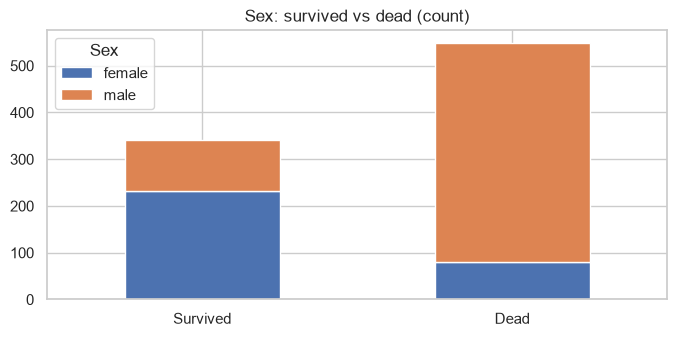

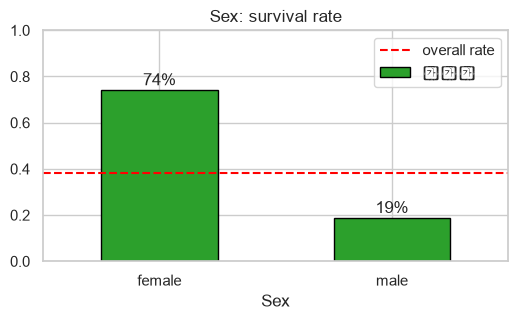

,인원,생존자,사망자,생존률
Sex,,,,
female,314,233,81,0.742
male,577,109,468,0.189


In [10]:
bar_chart('Sex')
survival_table('Sex')

 **결론:** 여성 생존률 **74%**, 남성 **19%**. 약 4배 차이로, 이 데이터에서 **가장 강력한 단서**입니다.
"여성은 생존, 남성은 사망"이라는 규칙 하나만으로 정확도가 **78.7%** 나옵니다(아래). 기준선 61.6%보다 17%p 높습니다.

 원본의 `train['Sex'] == 'Female'`은 항상 False였습니다. 실제 값은 소문자 `'female'`입니다.
글자 비교는 **대소문자까지** 정확히 맞아야 합니다.

In [11]:
rule = (train['Sex'] == 'female').astype(int)
print(f"'여성=생존' 규칙의 정확도: {(rule == train['Survived']).mean():.4f}")
print("대문자 'Female'과 같은 행 수:", (train['Sex'] == 'Female').sum(), "| 소문자 'female':", (train['Sex'] == 'female').sum())

'여성=생존' 규칙의 정확도: 0.7868
대문자 'Female'과 같은 행 수: 0 | 소문자 'female': 314


## 5-2 객실 등급 (Pclass)

 **가설:** 1등석은 갑판(구명보트)과 가깝고 사회적 지위가 높아 생존률이 높을 것이다.

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


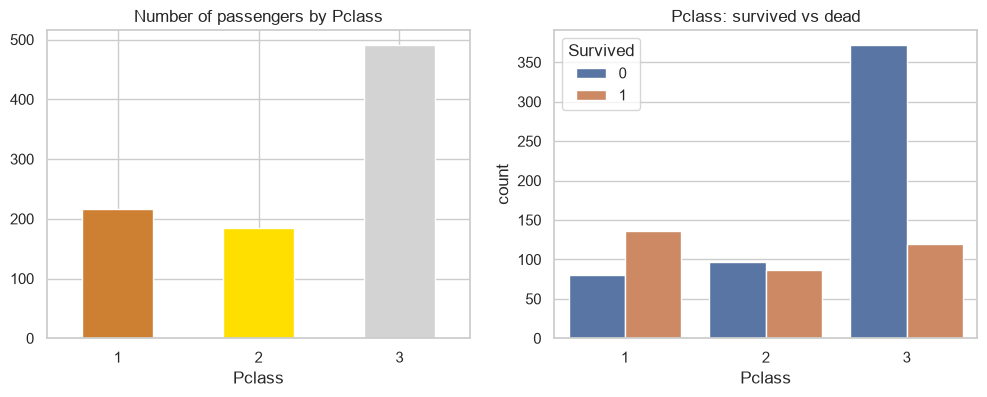

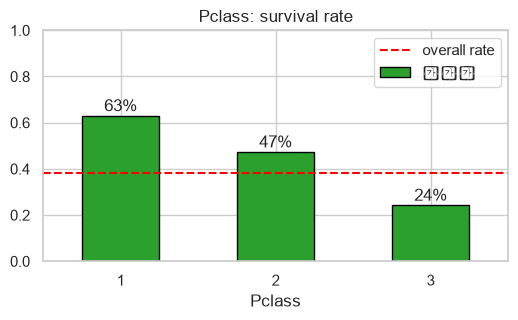

,인원,생존자,사망자,생존률
Pclass,,,,
1,216,136,80,0.630
2,184,87,97,0.473
3,491,119,372,0.242


In [12]:
display(pd.crosstab(train['Pclass'], train['Survived'], margins=True))
f, ax = plt.subplots(1, 2, figsize=(12, 4))
train['Pclass'].value_counts().sort_index().plot.bar(color=['#CD7F32', '#FFDF00', '#D3D3D3'], ax=ax[0], rot=0)
ax[0].set_title('Number of passengers by Pclass')
sns.countplot(x='Pclass', hue='Survived', data=train, ax=ax[1])
ax[1].set_title('Pclass: survived vs dead')
plt.show()
survival_table('Pclass')

 **결론:** 1등석 **63%** → 2등석 **47%** → 3등석 **24%**. 등급이 낮을수록 생존률이 뚜렷하게 떨어집니다.
승객의 55%(491명)가 3등석이라 전체 사망자의 다수가 3등석입니다.

## 5-3 성별 × 등급 — 두 변수를 함께 보기

 **질문:** 여성이 많이 살아남은 이유가 "여성이라서"일까, "여성이 1등석에 많아서"일까?
두 변수를 **동시에** 나눠 봐야 답할 수 있습니다.

생존률


Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


인원


Pclass,1,2,3
Sex,,,
female,94,76,144
male,122,108,347


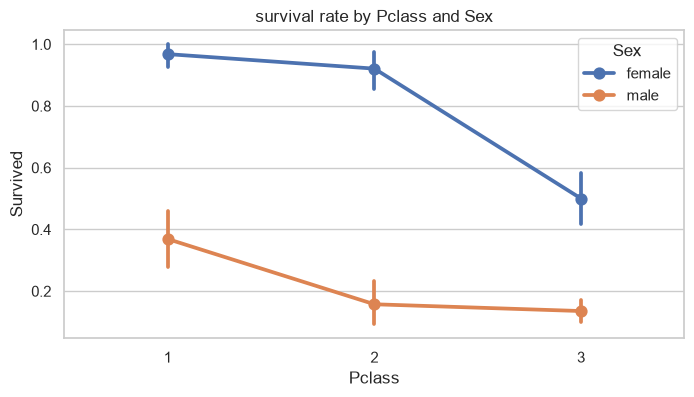

In [13]:
rate = pd.crosstab(train['Sex'], train['Pclass'], values=train['Survived'], aggfunc='mean').round(3)
count = pd.crosstab(train['Sex'], train['Pclass'])
print('생존률'); display(rate)
print('인원'); display(count)

sns.pointplot(x='Pclass', y='Survived', hue='Sex', data=train)
plt.title('survival rate by Pclass and Sex'); plt.show()

 **결론**

| | 1등석 | 2등석 | 3등석 |
|---|---|---|---|
| 여성 | **97%** | **92%** | 50% |
| 남성 | 37% | 16% | **14%** |

- 같은 등급 안에서도 여성이 압도적으로 높습니다 → **성별 자체의 효과**가 있습니다.
- 같은 성별 안에서도 등급이 높을수록 높습니다 → **등급 자체의 효과**도 있습니다.
- **3등석 여성(50%)** 과 **1등석 남성(37%)** 이 "애매한" 그룹입니다. 모델이 가장 많이 틀릴 곳으로 예상됩니다(13장에서 확인).

## 5-4 탑승 항구 (Embarked) — 겉보기 관계에 속지 않기

 **가설:** 항구가 생존에 직접 영향을 줄 이유는 없어 보인다. 그런데 차이가 난다면 왜일까?

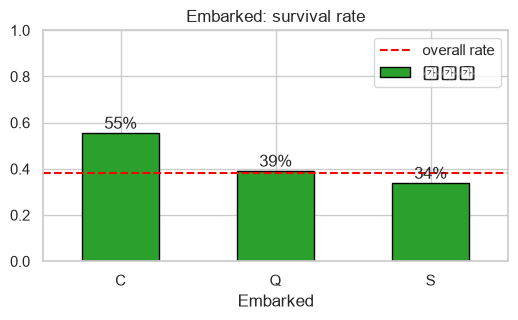

,인원,생존자,사망자,생존률
Embarked,,,,
C,168,93,75,0.554
Q,77,30,47,0.390
S,644,217,427,0.337


항구별 등급 구성 (행 기준 비율)


Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


항구별 여성 비율


Embarked
C    0.43
Q    0.47
S    0.32
Name: Sex, dtype: float64

In [14]:
display(survival_table('Embarked'))
print('항구별 등급 구성 (행 기준 비율)')
display(pd.crosstab(train['Embarked'], train['Pclass'], normalize='index').round(2))
print('항구별 여성 비율')
display(train.groupby('Embarked')['Sex'].apply(lambda s: (s == 'female').mean()).round(2))

 **결론:** Cherbourg(C) 탑승객의 생존률(55%)이 높습니다. 하지만 C 탑승객의 **51%가 1등석**입니다.
반대로 Queenstown(Q)은 94%가 3등석입니다.

>  **항구 자체가 원인이 아니라, 항구마다 등급 구성이 달라서 생긴 차이**일 가능성이 큽니다.
> 이렇게 두 변수가 함께 움직여 생기는 겉보기 관계를 조심해야 합니다. 모델에는 넣되, 큰 기대는 하지 않습니다.

## 5-5 함께 탄 가족 수 (SibSp, Parch)

 **가설:** 가족이 조금 있으면 서로 도와 생존에 유리하고, 너무 많으면 함께 움직이기 어려워 불리할 것이다.

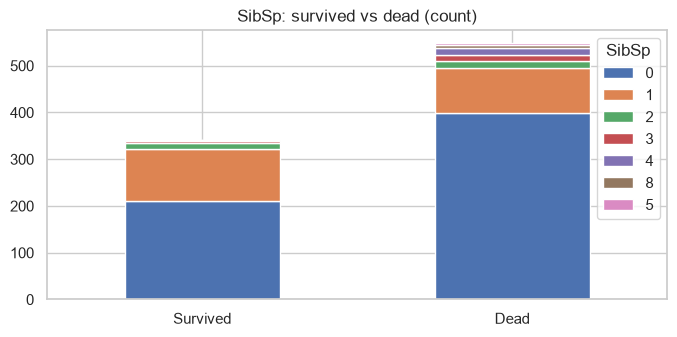

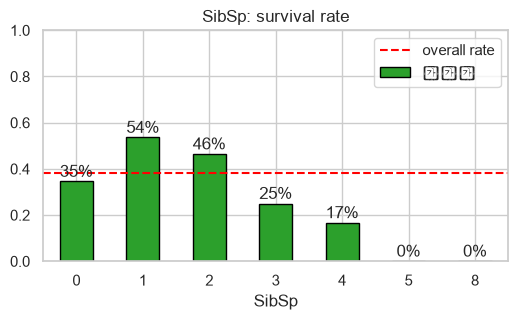

,인원,생존자,사망자,생존률
SibSp,,,,
0,608,210,398,0.345
1,209,112,97,0.536
2,28,13,15,0.464
3,16,4,12,0.250
4,18,3,15,0.167
5,5,0,5,0.000
8,7,0,7,0.000


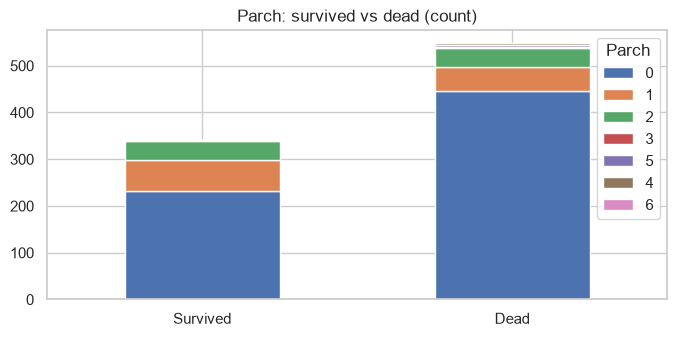

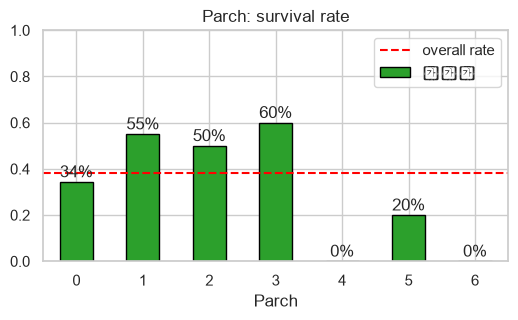

,인원,생존자,사망자,생존률
Parch,,,,
0,678,233,445,0.344
1,118,65,53,0.551
2,80,40,40,0.500
3,5,3,2,0.600
4,4,0,4,0.000
5,5,1,4,0.200
6,1,0,1,0.000


In [15]:
bar_chart('SibSp')
display(survival_table('SibSp'))
bar_chart('Parch')
display(survival_table('Parch'))

 **결론:** 혼자(0)보다 1~2명과 함께 탄 승객의 생존률이 높고, 가족이 많으면(SibSp 3 이상) 다시 낮아집니다.
**"적당한 가족이 유리"** 라는 가설과 맞습니다. 9장에서 두 열을 합친 `FamilySize`로 더 깔끔하게 봅니다.

 **인원이 적은 그룹의 비율은 믿기 어렵습니다.** SibSp = 5인 승객은 5명뿐입니다. 5명 중 0명 생존(0%)은
한두 명만 달랐어도 크게 바뀝니다. 비율 옆의 **인원 수를 꼭 함께 보세요.**

## 5-6 이 차이는 우연일까? — 섞어보기 실험

 그룹 간 생존률 차이가 "진짜"인지, 표본을 뽑을 때 생긴 **우연한 흔들림**인지 확인하는 간단한 방법입니다.

1. `Survived` 열을 무작위로 섞어 열과 생존의 관계를 **일부러 끊습니다.**
2. 섞은 데이터에서 "그룹 간 생존률의 최대 차이"를 계산합니다. → 관계가 없을 때 우연히 생기는 차이
3. 2000번 반복해서, **실제 차이보다 큰 경우가 몇 %인지**(우연 비율) 셉니다. 5% 미만이면 우연으로 보기 어렵습니다.

In [16]:
def shuffle_test(col, n=2000, data=None, seed=SEED):
    data = (train if data is None else data)[[col, 'Survived']].dropna()
    codes = data[col].astype('category').cat.codes.to_numpy()
    y = data['Survived'].to_numpy()
    size = np.bincount(codes)
    gap = lambda t: (np.bincount(codes, weights=t) / size).max() - (np.bincount(codes, weights=t) / size).min()
    rng = np.random.default_rng(seed)
    real = gap(y)
    fake = np.array([gap(rng.permutation(y)) for _ in range(n)])
    return real, (fake >= real).mean(), fake


rows = []
for col in ['Sex', 'Pclass', 'Embarked', 'SibSp', 'Parch']:
    real, chance, _ = shuffle_test(col)
    rows.append({'열': col, '실제 최대 차이': round(real, 3), '우연 비율': chance})
display(pd.DataFrame(rows))

,열,실제 최대 차이,우연 비율
0,Sex,0.553,0.0000
1,Pclass,0.387,0.0000
2,Embarked,0.217,0.0010
3,SibSp,0.536,0.1045
4,Parch,0.600,0.7380


 **결론**
- `Sex`, `Pclass`, `Embarked`: 우연 비율이 0에 가깝습니다. 2000번 섞어도 실제만큼 큰 차이가 거의 나오지 않으므로
  **생존과 관계가 있다**고 봅니다. (Embarked처럼 진짜 원인이 다른 변수에 있더라도 "관계"는 있습니다.)
- `SibSp`(0.10), `Parch`(0.74): **우연으로도 충분히 나올 수 있는 차이**로 나옵니다. 이상하지요? 5-5에서는 차이가 뚜렷해 보였는데요.
  이유는 **인원이 1~7명뿐인 범주**(SibSp 5·8, Parch 4·5·6) 때문입니다. 섞기만 해도 이런 작은 그룹에서는 0%나 100% 같은
  극단적인 비율이 쉽게 생기므로, "최대 차이"가 우연으로도 크게 나옵니다.

>  **작은 그룹은 판단을 흐립니다.** 9장에서 범주를 `혼자 / 소가족 / 대가족`으로 묶은 뒤 같은 실험을 다시 하면 결과가 달라집니다.

---
# 6. 수치형 변수와 생존 — 나이(Age), 요금(Fare)

## 6-1 나이 (Age)

 **가설:** "어린이 먼저" 원칙 때문에 어린이의 생존률이 높을 것이다.

가장 나이 많은 승객: 80.0세 | 가장 어린 승객: 0.42세 | 평균: 29.7세 | 중앙값: 28.0세


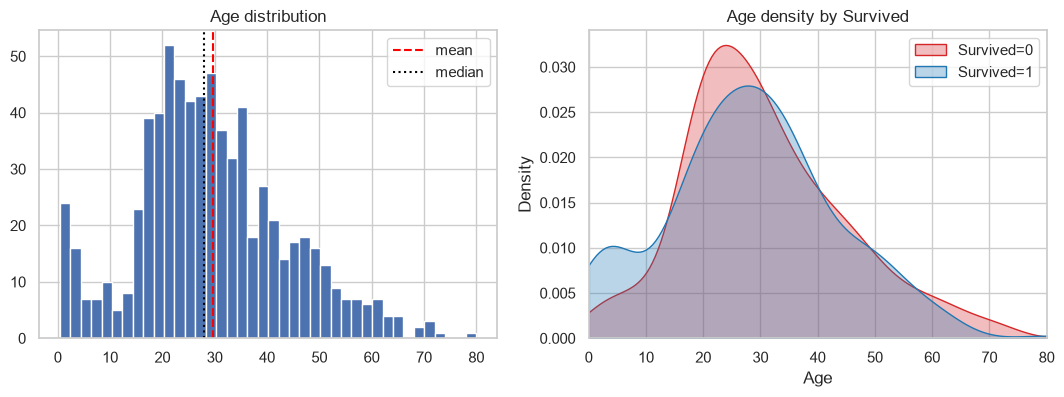

In [17]:
print(f"가장 나이 많은 승객: {train['Age'].max()}세 | 가장 어린 승객: {train['Age'].min()}세 | 평균: {train['Age'].mean():.1f}세 | 중앙값: {train['Age'].median()}세")

f, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(train['Age'].dropna(), bins=40, edgecolor='white')
ax[0].axvline(train['Age'].mean(), color='red', linestyle='--', label='mean')
ax[0].axvline(train['Age'].median(), color='black', linestyle=':', label='median')
ax[0].set_title('Age distribution'); ax[0].legend()
for label, color in [(0, 'tab:red'), (1, 'tab:blue')]:
    sns.kdeplot(train.loc[train['Survived'] == label, 'Age'].dropna(), fill=True, alpha=0.3,
                color=color, label=f'Survived={label}', ax=ax[1])
ax[1].set_xlim(0, train['Age'].max()); ax[1].set_title('Age density by Survived'); ax[1].legend()
plt.show()

 **그림 읽기**
- 왼쪽: 20~30대가 가장 많고, 평균(29.7)과 중앙값(28)이 비슷합니다 → 크게 치우치지 않았습니다.
- 오른쪽: **10세 이하**에서 파란색(생존)이 빨간색(사망)보다 높습니다 → 어린이는 생존이 더 많습니다.
  **20~30대**에서는 빨간색이 더 높습니다(원본의 "20~30대에 사망이 많다" 관찰과 같음). 이 연령대는 3등석 젊은 남성이 많기 때문입니다.

 원본의 `kdeplot(..., shade=True)`는 최신 seaborn에서 `fill=True`로 바뀌었습니다.

원본처럼 나이를 **구간으로 나눠(binning)** 생존률을 표로 봅니다. 원본 코드의 두 가지 오류를 고친 버전입니다.
- `(조건1) and (조건2)` → pandas에서는 `&`를 써야 합니다 (원본 셀의 `ValueError` 원인).
- 구간 번호로 `Age` 열을 **덮어쓰면** 원래 나이를 잃고, 그 뒤 숫자 비교가 `TypeError`를 냅니다 → **새 열**을 만들고 `pd.cut`을 씁니다.

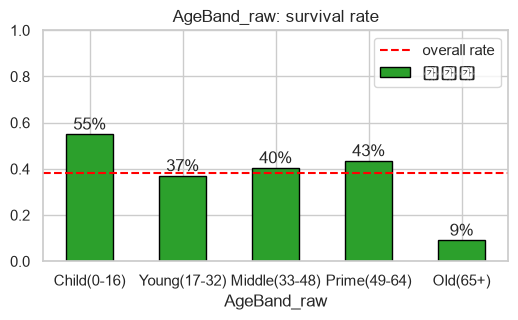

,인원,생존자,사망자,생존률
AgeBand_raw,,,,
Child(0-16),100,55,45,0.550
Young(17-32),346,128,218,0.370
Middle(33-48),188,76,112,0.404
Prime(49-64),69,30,39,0.435
Old(65+),11,1,10,0.091


10세 이하 64명의 생존률: 59.4% (전체 38.4%)


In [18]:
age_bins = [0, 16, 32, 48, 64, 80]
age_labels = ['Child(0-16)', 'Young(17-32)', 'Middle(33-48)', 'Prime(49-64)', 'Old(65+)']
train['AgeBand_raw'] = pd.cut(train['Age'], bins=age_bins, labels=age_labels)
display(survival_table('AgeBand_raw'))
train = train.drop(columns='AgeBand_raw')

kids = train[train['Age'] <= 10]
print(f"10세 이하 {len(kids)}명의 생존률: {kids['Survived'].mean():.1%} (전체 {train['Survived'].mean():.1%})")

 **결론:** 0~16세 생존률 **55%** 로 전체(38%)보다 높고, 65세 이상은 11명 중 1명만 생존했습니다(인원이 적어 참고만).
17~64세 사이에서는 큰 차이가 없습니다. → 나이의 효과는 주로 **"어린이인가"** 에서 나옵니다.

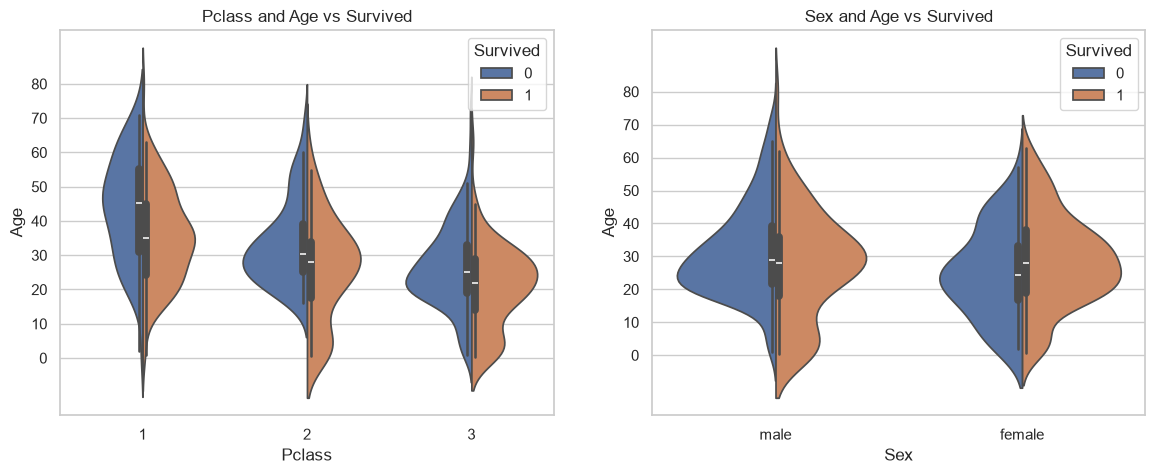

In [19]:
f, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(x='Pclass', y='Age', hue='Survived', data=train, split=True, ax=ax[0])
ax[0].set_title('Pclass and Age vs Survived'); ax[0].set_yticks(range(0, 90, 10))
sns.violinplot(x='Sex', y='Age', hue='Survived', data=train, split=True, ax=ax[1])
ax[1].set_title('Sex and Age vs Survived'); ax[1].set_yticks(range(0, 90, 10))
plt.show()

 **바이올린 그림 읽기** (원본 그림) — 남성 쪽에서 **어린 남자아이**는 생존(주황)이 두껍습니다.
성인 남성은 사망(파랑)이 압도적입니다. 남성 안에서는 "어린이인가"가 생존을 크게 가릅니다.
→ 이 정보는 7장의 호칭 **Master(남자아이)** 로 깔끔하게 잡힙니다.

## 6-2 요금 (Fare)

 **가설:** 비싼 요금 = 높은 등급 = 생존률이 높을 것이다.

평균 32.2 | 중앙값 14.5 | 최대 512.3 | 왜도 4.79 | 요금 0인 승객 15명


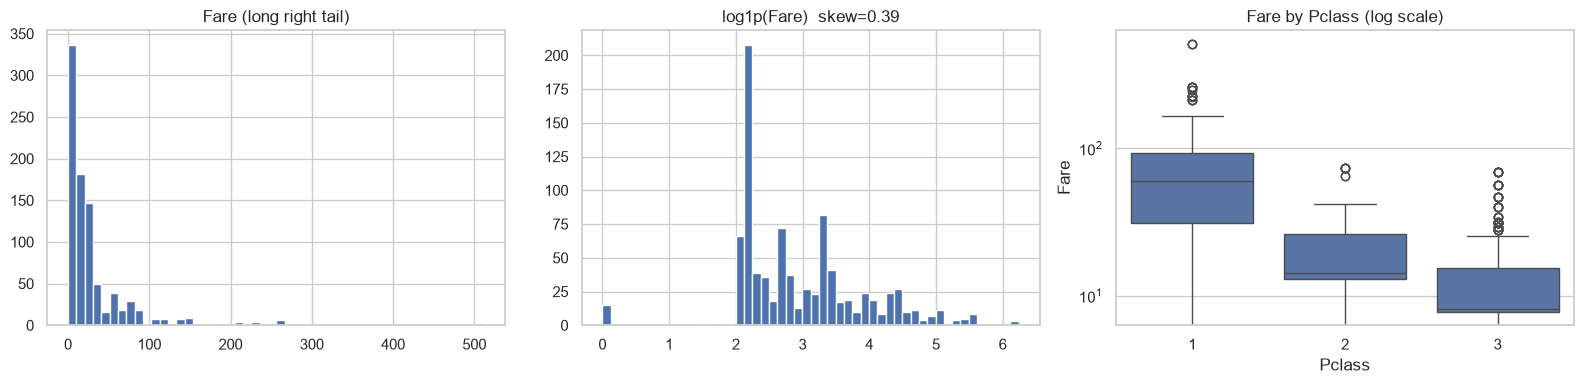

In [20]:
print(f"평균 {train['Fare'].mean():.1f} | 중앙값 {train['Fare'].median():.1f} | 최대 {train['Fare'].max():.1f} | "
      f"왜도 {train['Fare'].skew():.2f} | 요금 0인 승객 {(train['Fare'] == 0).sum()}명")
f, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(train['Fare'], bins=50, edgecolor='white'); ax[0].set_title('Fare (long right tail)')
ax[1].hist(np.log1p(train['Fare']), bins=50, edgecolor='white')
ax[1].set_title(f"log1p(Fare)  skew={np.log1p(train['Fare']).skew():.2f}")
sns.boxplot(x='Pclass', y='Fare', data=train, ax=ax[2]); ax[2].set_yscale('log'); ax[2].set_title('Fare by Pclass (log scale)')
plt.tight_layout(); plt.show()

- 요금은 **오른쪽으로 아주 긴 꼬리**(왜도 4.8)가 있습니다. 평균(32.2)이 중앙값(14.5)의 두 배가 넘습니다.
- `log1p`(= log(1 + 요금))를 씌우면 왜도가 0.4로 줄어 훨씬 고르게 퍼집니다. 선형 모델에는 이 변환이 도움이 됩니다.
- 등급별 상자그림: 1등석 요금이 압도적으로 높습니다. **요금과 등급은 많이 겹치는 정보**입니다.
- 요금 0인 승객 15명이 있습니다(승무원 관계자 등으로 추정). 오류로 단정할 수 없어 그대로 둡니다.

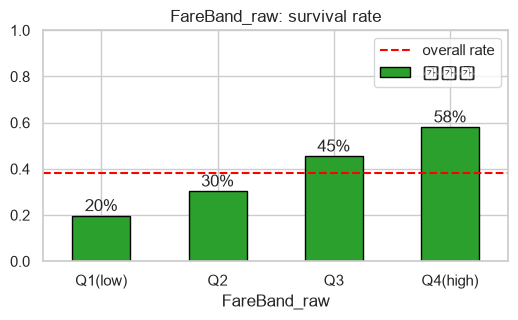

,인원,생존자,사망자,생존률
FareBand_raw,,,,
Q1(low),223,44,179,0.197
Q2,224,68,156,0.304
Q3,222,101,121,0.455
Q4(high),222,129,93,0.581


In [21]:
train['FareBand_raw'] = pd.qcut(train['Fare'], 4, labels=['Q1(low)', 'Q2', 'Q3', 'Q4(high)'])
display(survival_table('FareBand_raw'))
train = train.drop(columns='FareBand_raw')

 **결론:** 요금을 4등분하면 가장 싼 구간 **20%** → 가장 비싼 구간 **58%**. 가설과 맞습니다.
`pd.qcut`은 **인원이 같도록** 나누고, `pd.cut`은 **값의 폭이 같도록** 나눕니다. 꼬리가 긴 요금에는 `qcut`이 적합합니다.

---
# 7. 이름에서 호칭(Title) 뽑기

 이름 891개는 모두 달라서 그대로는 쓸 수 없습니다. 하지만 `Braund, **Mr.** Owen Harris`처럼
이름 가운데의 **호칭**에는 성별, 나이대(Master = 남자아이, Miss = 미혼 여성), 신분(Dr, Rev, Countess)이 담겨 있습니다.

 **정규표현식 `' ([A-Za-z]+)\.'` 해석**

| 조각 | 뜻 |
|---|---|
| `' '` | 공백 하나 (성 뒤의 `, ` 다음) |
| `([A-Za-z]+)` | 영문자가 1개 이상 이어진 부분 — **괄호 안이 뽑아낼 부분** |
| `\.` | 마침표 문자 그대로 (`.`만 쓰면 "아무 글자"라는 뜻이 됨) |

→ "공백 + 영어 단어 + 마침표" 모양을 찾아 단어만 꺼냅니다. 파이썬 문자열 앞에 `r`을 붙이면(`r' ([A-Za-z]+)\.'`)
`\`를 그대로 전달해 경고가 나지 않습니다.

In [22]:
for df in [train, test]:
    df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

print('train 호칭:', train['Title'].value_counts().to_dict())
print('test  호칭:', test['Title'].value_counts().to_dict())
display(pd.crosstab(train['Title'], train['Sex']).T)

train 호칭: {'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'Countess': 1, 'Jonkheer': 1}
test  호칭: {'Mr': 240, 'Miss': 78, 'Mrs': 72, 'Master': 21, 'Col': 2, 'Rev': 2, 'Ms': 1, 'Dr': 1, 'Dona': 1}


Title,Capt,Col,Countess,Don,Dr,Jonkheer,Lady,Major,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir
Sex,,,,,,,,,,,,,,,,,
female,0,0,1,0,1,0,1,0,0,182,2,1,0,125,1,0,0
male,1,2,0,1,6,1,0,2,40,0,0,0,517,0,0,6,1


Mr(517), Miss(182), Mrs(125), Master(40)가 대부분이고, 나머지는 1~7명뿐입니다.

**test에는 train에 없는 `Dona`가 있습니다.** 그대로 두면 모델이 처음 보는 값이 됩니다.

인원이 적은 호칭은 비슷한 것끼리 묶습니다.

| 원래 호칭 | 묶은 결과 | 이유 |
|---|---|---|
| Mlle, Ms | Miss | 프랑스어 / 다른 표기의 미혼 여성 |
| Mme | Mrs | 프랑스어 기혼 여성 |
| Dr, Rev, Col, Major, Capt, Sir, Don, Jonkheer, Lady, Countess, Dona | Rare | 인원이 너무 적은 직업·귀족 호칭 |

 원본은 호칭을 숫자(0~3)로 바꾼 뒤 다시 이름에서 추출하는 등 순서가 꼬여 있었습니다. 여기서는 **글자 그대로 정리**하고,
숫자 변환은 모델 직전에 원-핫 인코딩으로 한 번에 합니다.

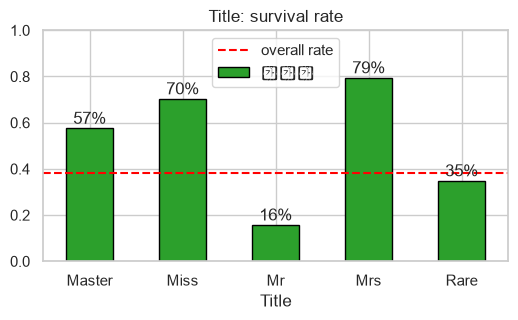

,인원,생존자,사망자,생존률
Title,,,,
Master,40,23,17,0.575
Miss,185,130,55,0.703
Mr,517,81,436,0.157
Mrs,126,100,26,0.794
Rare,23,8,15,0.348


,count,mean,median
Title,,,
Master,36,4.6,3.5
Miss,149,21.8,21.0
Mr,398,32.4,30.0
Mrs,109,35.8,35.0
Rare,22,45.5,48.5


In [23]:
title_map = {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}
common = ['Mr', 'Miss', 'Mrs', 'Master']
for df in [train, test]:
    df['Title'] = df['Title'].replace(title_map)
    df['Title'] = df['Title'].where(df['Title'].isin(common), 'Rare')

display(survival_table('Title'))
display(train.groupby('Title')['Age'].agg(['count', 'mean', 'median']).round(1))

 **결론**

| 호칭 | 생존률 | 평균 나이 | 해석 |
|---|---|---|---|
| Mr | **16%** | 32세 | 성인 남성 — 가장 낮음 |
| Master | **58%** | 4.6세 | **남자아이** — 남성인데도 생존률이 높음 ("어린이 먼저") |
| Miss | 70% | 22세 | 미혼 여성·여자아이 |
| Mrs | 79% | 36세 | 기혼 여성 |
| Rare | 35% | 46세 | 대부분 남성 직업·귀족 호칭 |

>  호칭은 **성별 + 나이대**를 한꺼번에 담은 특성입니다. 특히 Sex만으로는 구분 못 하는 "남자아이(Master)"를 잡아냅니다.
> 호칭별 나이가 이렇게 다르니, **나이 결측을 호칭별 중앙값으로 채우는 것**이 전체 중앙값보다 훨씬 정확합니다(다음 장).

---
# 8. 결측값 채우기

**원칙: 채우는 값은 train에서만 계산하고, test에는 그 값을 그대로 적용합니다.**
원본은 test의 나이를 **test 자신의 중앙값**으로 채웠습니다. 그러면 train과 test에 서로 다른 기준이 적용되고,
실제 대회에서 test가 한 줄씩 들어오는 상황이라면 계산 자체가 불가능합니다.

## 8-1 나이: 호칭별 중앙값 (train 기준)

호칭별 나이 중앙값 (train에서 계산):
Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64


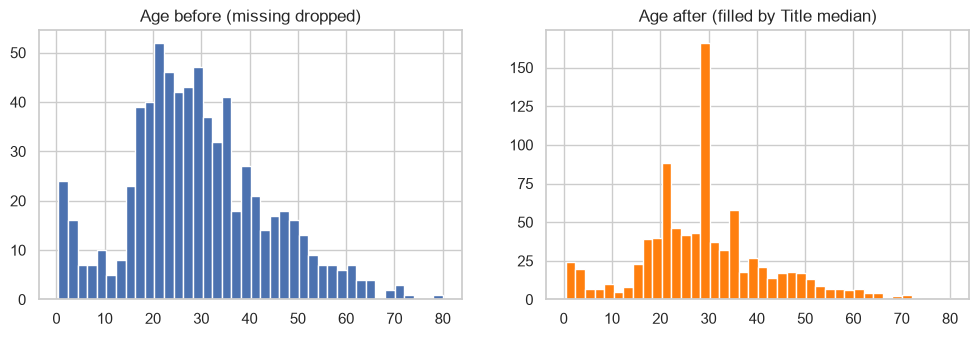

남은 결측 — train: 0 | test: 0


In [24]:
age_by_title = train.groupby('Title')['Age'].median()
print('호칭별 나이 중앙값 (train에서 계산):'); print(age_by_title)

for df in [train, test]:
    df['AgeMissing'] = df['Age'].isna().astype(int)           # 3장: 비어 있었다는 사실도 정보로 남김
    df['Age'] = df['Age'].fillna(df['Title'].map(age_by_title))

f, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(raw_train['Age'].dropna(), bins=40, edgecolor='white'); ax[0].set_title('Age before (missing dropped)')
ax[1].hist(train['Age'], bins=40, edgecolor='white', color='tab:orange'); ax[1].set_title('Age after (filled by Title median)')
plt.show()
print('남은 결측 — train:', train['Age'].isna().sum(), '| test:', test['Age'].isna().sum())

전체 중앙값(28) 하나로 채웠다면 177명이 모두 28세가 되어 막대 하나가 비정상적으로 솟았을 것입니다.
호칭별로 채우면 Master는 3.5세, Mrs는 35세 등으로 나뉘어 **원래 분포 모양을 더 잘 유지**합니다.
`AgeMissing` 열로 "원래 비어 있었다"는 정보도 남겨 두었습니다(3장에서 생존률이 달랐음).

## 8-2 탑승 항구 2명, 요금 1명

In [25]:
display(raw_train[raw_train['Embarked'].isna()][['PassengerId', 'Name', 'Pclass', 'Fare', 'Cabin', 'Ticket']])
embarked_mode = train['Embarked'].mode()[0]
print('Embarked 최빈값:', embarked_mode)
print('참고 — 1등석이면서 요금 70~90인 승객의 항구 분포:',
      train[(train['Pclass'] == 1) & train['Fare'].between(70, 90)]['Embarked'].value_counts().to_dict())
train['Embarked'] = train['Embarked'].fillna(embarked_mode)

fare_by_class = train.groupby('Pclass')['Fare'].median()
display(test[test['Fare'].isna()][['PassengerId', 'Name', 'Pclass', 'Embarked']])
test['Fare'] = test['Fare'].fillna(test['Pclass'].map(fare_by_class))
print('test Fare 결측을 3등석 train 중앙값', fare_by_class[3], '으로 채움 (원본은 0으로 채움)')

,PassengerId,Name,Pclass,Fare,Cabin,Ticket
61,62,"Icard, Miss. Amelie",1,80.0,B28,113572
829,830,"Stone, Mrs. George Nelson (Martha Evelyn)",1,80.0,B28,113572


Embarked 최빈값: S
참고 — 1등석이면서 요금 70~90인 승객의 항구 분포: {'S': 20, 'C': 19, 'Q': 2}


,PassengerId,Name,Pclass,Embarked
152,1044,"Storey, Mr. Thomas",3,S


test Fare 결측을 3등석 train 중앙값 8.05 으로 채움 (원본은 0으로 채움)


- `Embarked` 결측 2명은 같은 티켓(113572)·같은 객실(B28)의 1등석 일행입니다. 최빈값 **S**로 채웁니다.
  (같은 조건 승객의 항구 분포를 보면 S와 C가 섞여 있어 어느 쪽이든 큰 차이는 없습니다.)
- test의 `Fare` 결측 1명은 3등석이므로 **train 3등석 요금 중앙값**으로 채웁니다.
  원본처럼 0으로 채우면 "공짜 승객"이라는 다른 뜻이 됩니다.

---
# 9. 새 특성 만들기 — 가족, 객실, 티켓

새 특성은 **입력 열끼리만** 계산합니다. 정답(`Survived`)을 써서 만든 특성은 검증 점수를 거짓으로 부풀리기 때문에 쓰지 않습니다.

## 9-1 가족 규모 (FamilySize)

`FamilySize = SibSp + Parch + 1` — **+1은 본인**입니다. (원본 주석의 "파이썬이 0부터 세기 때문"이 아니라, 동반 가족 수에 자기 자신을 더한 것입니다.)

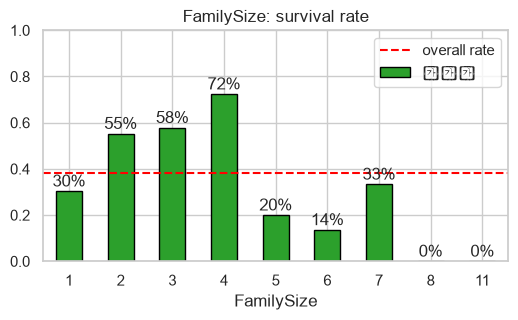

,인원,생존자,사망자,생존률
FamilySize,,,,
1,537,163,374,0.304
2,161,89,72,0.553
3,102,59,43,0.578
4,29,21,8,0.724
5,15,3,12,0.200
6,22,3,19,0.136
7,12,4,8,0.333
8,6,0,6,0.000
11,7,0,7,0.000


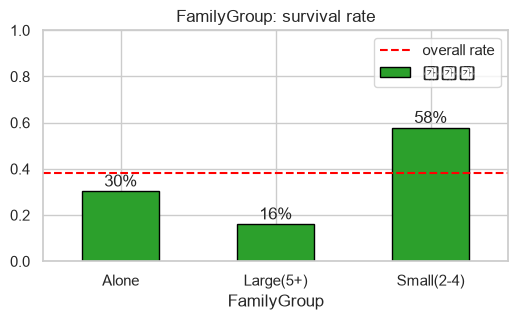

,인원,생존자,사망자,생존률
FamilyGroup,,,,
Alone,537,163,374,0.304
Large(5+),62,10,52,0.161
Small(2-4),292,169,123,0.579


섞어보기 실험 — SibSp        실제 최대 차이 0.536 | 우연 비율 0.1045
섞어보기 실험 — Parch        실제 최대 차이 0.600 | 우연 비율 0.7380


섞어보기 실험 — FamilyGroup  실제 최대 차이 0.417 | 우연 비율 0.0000


In [26]:
for df in [train, test]:
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['FamilyGroup'] = pd.cut(df['FamilySize'], bins=[0, 1, 4, 20], labels=['Alone', 'Small(2-4)', 'Large(5+)']).astype(str)

display(survival_table('FamilySize'))
display(survival_table('FamilyGroup'))
for col in ['SibSp', 'Parch', 'FamilyGroup']:
    real, chance, _ = shuffle_test(col)
    print(f'섞어보기 실험 — {col:12s} 실제 최대 차이 {real:.3f} | 우연 비율 {chance:.4f}')

**결론:** 혼자 **30%** → 2~4명 가족 **58%** (4명 가족은 72%) → 5명 이상 **16%**.
5장의 가설("적당한 가족이 유리, 대가족은 불리")이 훨씬 또렷하게 보입니다.
인원이 적은 큰 숫자들을 **3그룹으로 묶자** 섞어보기 실험의 우연 비율이 0에 가까워졌습니다.
5-6에서 SibSp·Parch가 "우연일 수 있다"고 나왔던 것은 관계가 없어서가 아니라 **작은 그룹들 때문에 측정이 흐려졌기 때문**입니다.
원본의 "혼자일 경우 사망률이 높다"는 관찰과도 일치합니다.

## 9-2 객실 정보 — 기록 유무(HasCabin)와 갑판(Deck)

객실 번호의 첫 글자(A~G)는 **갑판 층**입니다. A가 가장 위층(구명보트와 가까움)입니다.

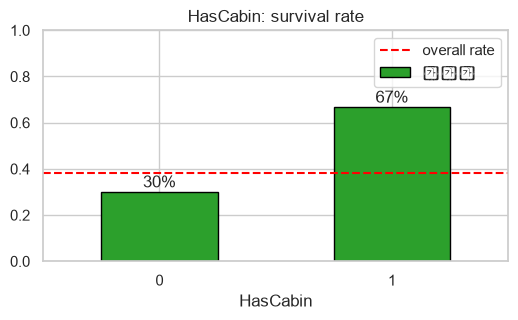

,인원,생존자,사망자,생존률
HasCabin,,,,
0,687,206,481,0.300
1,204,136,68,0.667


HasCabin,기록 없음,기록 있음
Pclass,,
1,0.19,0.81
2,0.91,0.09
3,0.98,0.02


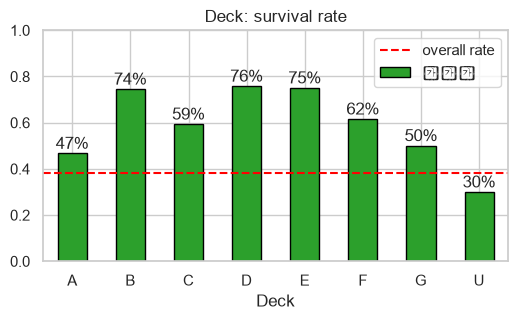

,인원,생존자,사망자,생존률
Deck,,,,
A,15,7,8,0.467
B,47,35,12,0.745
C,59,35,24,0.593
D,33,25,8,0.758
E,32,24,8,0.750
F,13,8,5,0.615
G,4,2,2,0.500
U,688,206,482,0.299


In [27]:
for df in [train, test]:
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    df['Deck'] = df['Cabin'].str[0].fillna('U')                 # U = Unknown(기록 없음)
    df['Deck'] = df['Deck'].replace({'T': 'U'})                  # T 갑판은 1명뿐 → 기록 없음과 합침

display(survival_table('HasCabin'))
display(pd.crosstab(train['Pclass'], train['HasCabin'], normalize='index').round(2).rename(columns={0: '기록 없음', 1: '기록 있음'}))
display(survival_table('Deck'))

**결론:** 객실 기록이 있으면 생존률 **67%**, 없으면 **30%**. 하지만 1등석의 81%는 기록이 있고 3등석은 2%만 있습니다.
즉 `HasCabin`은 **등급과 상당 부분 겹치는 정보**입니다. 갑판별로는 B·D·E가 70% 이상으로 높지만 갑판마다 인원이 적습니다.

## 9-3 같은 티켓 인원 (TicketGroup)

같은 티켓 번호 = 함께 표를 산 일행입니다. 가족이 아닌 친구·하인 일행도 잡을 수 있습니다.
인원을 셀 때는 **train과 test의 티켓을 합쳐서** 셉니다(정답을 쓰지 않으므로 반칙이 아닙니다).

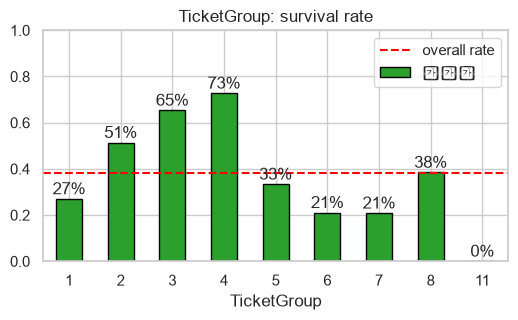

,인원,생존자,사망자,생존률
TicketGroup,,,,
1,481,130,351,0.270
2,181,93,88,0.514
3,101,66,35,0.653
4,44,32,12,0.727
5,21,7,14,0.333
6,19,4,15,0.211
7,24,5,19,0.208
8,13,5,8,0.385
11,7,0,7,0.000


FamilySize와 TicketGroup이 다른 승객 비율: 0.219


In [28]:
ticket_counts = pd.concat([train['Ticket'], test['Ticket']]).value_counts()
for df in [train, test]:
    df['TicketGroup'] = df['Ticket'].map(ticket_counts)

display(survival_table('TicketGroup'))
print('FamilySize와 TicketGroup이 다른 승객 비율:', round((train['FamilySize'] != train['TicketGroup']).mean(), 3))

 티켓 일행 2~4명의 생존률이 높고 혼자이거나 5명 이상이면 낮습니다. 가족 규모와 비슷한 모양이지만,
**승객 약 5명 중 1명(22%)은 가족 수와 티켓 일행 수가 다릅니다** → 서로 다른 정보를 일부 담고 있습니다.

## 9-4 요금 로그 변환

6-2에서 본 긴 꼬리를 줄이기 위해 `FareLog = log(1 + Fare)`를 만듭니다. 한 장의 티켓 요금이 일행 전체의 요금인 경우가 많아,
**1인당 요금**(`Fare ÷ TicketGroup`)도 함께 만들어 봅니다.

In [29]:
for df in [train, test]:
    df['FareLog'] = np.log1p(df['Fare'])
    df['FarePerPerson'] = np.log1p(df['Fare'] / df['TicketGroup'])
    df['IsChild'] = (df['Age'] <= 12).astype(int)

display(train[['Fare', 'FareLog', 'TicketGroup', 'FarePerPerson', 'Age', 'IsChild']].head())

,Fare,FareLog,TicketGroup,FarePerPerson,Age,IsChild
0,7.2500,2.110213,1,2.110213,22.0,0
1,71.2833,4.280593,2,3.601186,38.0,0
2,7.9250,2.188856,1,2.188856,26.0,0
3,53.1000,3.990834,2,3.316003,35.0,0
4,8.0500,2.202765,1,2.202765,35.0,0


---
# 10. 특성 간 상관관계

숫자 특성끼리의 상관계수(−1 ~ +1)를 한눈에 봅니다. **Survived와의 상관**은 단서의 강도를,
**특성끼리의 높은 상관**(0.7 이상)은 겹치는 정보를 알려 줍니다.

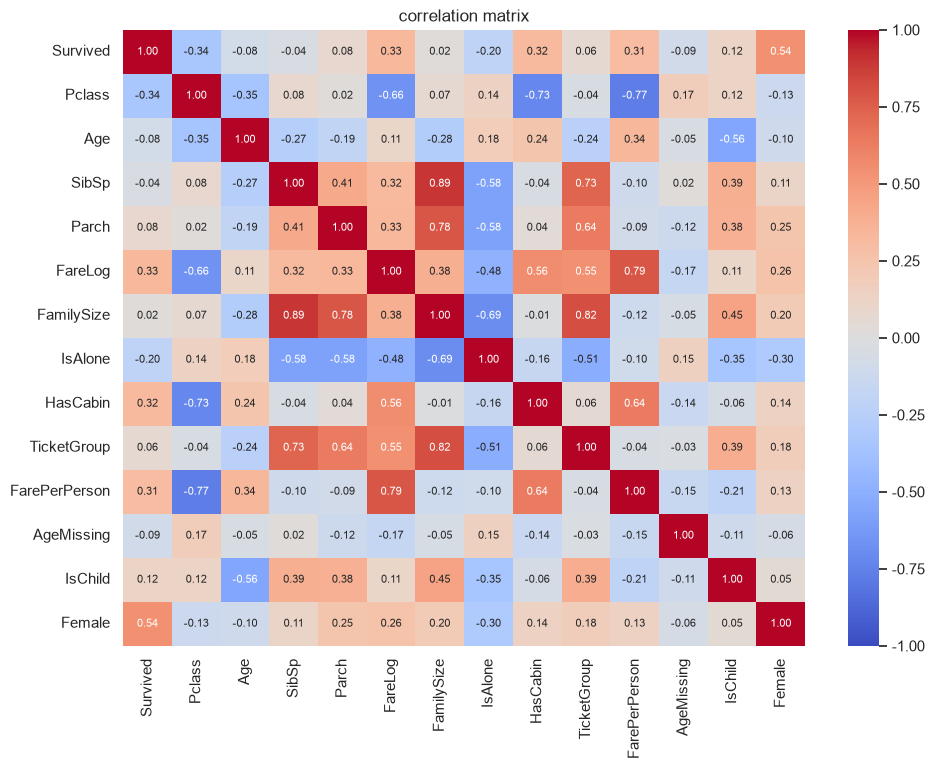

,Survived와의 상관
Female,0.543
Pclass,-0.338
FareLog,0.330
HasCabin,0.317
FarePerPerson,0.306
IsAlone,-0.203
IsChild,0.118
AgeMissing,-0.092
Parch,0.082
Age,-0.079


In [30]:
corr_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'FareLog', 'FamilySize', 'IsAlone',
             'HasCabin', 'TicketGroup', 'FarePerPerson', 'AgeMissing', 'IsChild']
corr_df = train[corr_cols].assign(Female=(train['Sex'] == 'female').astype(int))
corr = corr_df.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('correlation matrix'); plt.show()
display(corr['Survived'].drop('Survived').sort_values(key=abs, ascending=False).round(3).to_frame('Survived와의 상관'))

 **결론**
- 생존과 가장 강한 관계: **여성(+0.54)**, **등급(−0.34, 등급 숫자가 클수록 낮음)**, **객실 기록(+0.32)**, 요금(+0.33 안팎).
- 겹치는 정보: `Pclass` ↔ `FareLog` ↔ `HasCabin` ↔ `FarePerPerson`이 서로 강하게 얽혀 있습니다(모두 "부유함"의 신호).
  `FamilySize` ↔ `SibSp`·`Parch`·`TicketGroup`도 마찬가지입니다.
- `FamilySize`의 상관이 거의 0인 이유: 관계가 **직선이 아니라 산 모양**(혼자 낮음 → 소가족 높음 → 대가족 낮음)이라서입니다.
  상관계수는 직선 관계만 잽니다. 그래서 `FamilyGroup` 같은 구간 특성이 필요합니다.

---
# 11. 모델링

## 11-1 왜 LinearRegression이 아닌가

원본은 `LinearRegression`으로 학습하고 `score()`를 **학습 데이터에** 매겼습니다. 두 가지 문제가 있습니다.

| 문제 | 설명 |
|---|---|
| 회귀 모델로 분류를 함 | `LinearRegression`은 숫자를 맞히는 모델이라 0.3, 1.2, −0.1 같은 값을 냅니다. 생존 여부(0/1)를 직접 내지 않고, 0~1 범위도 벗어납니다 |
| `score()`가 정확도가 아님 | `LinearRegression.score()`는 R²(설명된 분산 비율)입니다. Kaggle 채점(정확도)과 다른 숫자입니다 |
| 학습 데이터로 채점 | 문제를 미리 본 시험처럼 점수가 부풀려집니다. **교차검증**으로 채점해야 합니다 |

분류에는 **0/1 또는 "1일 확률(0~1)"** 을 내는 분류 모델(예: `LogisticRegression`)을 씁니다. 직접 확인합니다.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

y = train['Survived']
simple = train[['Pclass', 'Age', 'SibSp', 'Parch', 'FareLog']].assign(Female=(train['Sex'] == 'female').astype(int))

lin = LinearRegression().fit(simple, y)
lin_pred = lin.predict(simple)
print(f'LinearRegression 예측값 범위: {lin_pred.min():.2f} ~ {lin_pred.max():.2f}  (0 미만 {int((lin_pred < 0).sum())}명, 1 초과 {int((lin_pred > 1).sum())}명)')
print(f'LinearRegression.score() = {lin.score(simple, y):.3f}  ← 정확도가 아니라 R²')

log = LogisticRegression(max_iter=1000).fit(simple, y)
proba = log.predict_proba(simple)[:, 1]
print(f'LogisticRegression 확률 범위: {proba.min():.2f} ~ {proba.max():.2f}  → predict()는 0/1:', sorted(set(log.predict(simple))))

LinearRegression 예측값 범위: -0.31 ~ 1.14  (0 미만 29명, 1 초과 32명)
LinearRegression.score() = 0.402  ← 정확도가 아니라 R²
LogisticRegression 확률 범위: 0.00 ~ 0.98  → predict()는 0/1: [np.int64(0), np.int64(1)]


선형 회귀는 0보다 작거나 1보다 큰 "생존 정도"를 냅니다. 로지스틱 회귀는 항상 0~1 사이의 **확률**을 내고,
`predict()`는 0.5를 기준으로 0/1을 돌려줍니다. 이제 채점을 정직하게 하기 위해 **교차검증**을 준비합니다.

## 11-2 교차검증과 전처리 파이프라인

**5겹 교차검증 × 3회 반복** — train을 5조각으로 나눠 돌아가며 1조각으로 채점하고, 나누는 방법을 바꿔 3번 반복합니다.
점수 15개의 **평균이 실력**, **표준편차가 흔들림**입니다. 모든 모델이 **같은 나눔(`cv`)** 으로 비교됩니다.

**파이프라인** — 숫자 열은 표준화, 글자 열은 원-핫 인코딩을 한 뒤 모델에 넣습니다.
원본은 원-핫 인코딩이 어려워 `Name`, `Ticket`, `Cabin`, `Embarked`, `Age`, `Title`을 모두 지웠지만,
여기서는 `OneHotEncoder`로 한 번에 처리합니다. `handle_unknown='ignore'`는 test에만 있는 값이 나와도 오류 없이 넘어가게 합니다.

In [32]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

NUM_ALL = ['Pclass', 'Age', 'SibSp', 'Parch', 'FareLog', 'FamilySize', 'IsAlone', 'HasCabin',
           'TicketGroup', 'FarePerPerson', 'AgeMissing', 'IsChild']
CAT_ALL = ['Sex', 'Embarked', 'Title', 'FamilyGroup', 'Deck']


def make_pipe(model, num=NUM_ALL, cat=CAT_ALL):
    prep = ColumnTransformer([('num', StandardScaler(), list(num)),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), list(cat))])
    return Pipeline([('prep', prep), ('model', model)])


def evaluate(pipe, cols, name):
    r = cross_validate(pipe, train[cols], y, cv=cv, scoring='accuracy', return_train_score=True, n_jobs=-1)
    return {'모델': name, '검증 정확도 평균': r['test_score'].mean(), '검증 표준편차': r['test_score'].std(),
            '학습 정확도': r['train_score'].mean(), '과적합 차이(학습-검증)': r['train_score'].mean() - r['test_score'].mean(),
            'scores': r['test_score']}

print('교차검증 회차 수:', cv.get_n_splits(), '| 숫자 특성', len(NUM_ALL), '개 | 글자 특성', len(CAT_ALL), '개')

교차검증 회차 수: 15 | 숫자 특성 12 개 | 글자 특성 5 개


## 11-3 모델 7종 비교

| 모델 | 아이디어 |
|---|---|
| 기준선 (Dummy) | 전부 "사망" |
| 성별 규칙 | `Sex` 하나로 깊이 1짜리 나무 = "여성은 생존" |
| 로지스틱 회귀 | 특성마다 가중치를 곱해 더한 뒤 확률로 변환 |
| K-최근접 이웃 | 가장 비슷한 승객 15명의 다수결 |
| 결정 나무 (제한 없음) | 예/아니오 질문을 끝까지 쪼갬 → 과적합 예시 |
| 랜덤 포레스트 | 나무 300그루의 다수결 |
| 그래디언트 부스팅 | 앞 나무가 틀린 것을 다음 나무가 고쳐 나감 |
| SVM | 두 그룹 사이의 경계를 가장 넓게 |

,검증 정확도 평균,검증 표준편차,학습 정확도,과적합 차이(학습-검증)
모델,,,,
그래디언트 부스팅,0.8316,0.0159,0.9197,0.0880
랜덤 포레스트,0.8264,0.0145,0.9009,0.0745
SVM,0.8257,0.0209,0.8464,0.0208
로지스틱 회귀,0.8245,0.0221,0.8398,0.0153
K-최근접 이웃,0.8047,0.0217,0.8312,0.0265
성별 규칙,0.7867,0.0209,0.7868,0.0000
결정 나무(제한 없음),0.7867,0.0236,0.9890,0.2022
기준선(전부 사망),0.6162,0.0023,0.6162,-0.0000


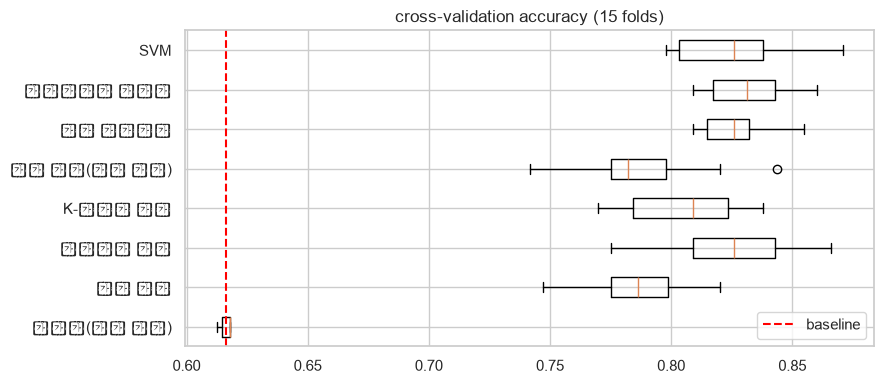

In [33]:
FEATURES_ALL = NUM_ALL + CAT_ALL
candidates = [
    (make_pipe(DummyClassifier(strategy='most_frequent')), FEATURES_ALL, '기준선(전부 사망)'),
    (make_pipe(DecisionTreeClassifier(max_depth=1), num=[], cat=['Sex']), ['Sex'], '성별 규칙'),
    (make_pipe(LogisticRegression(max_iter=2000)), FEATURES_ALL, '로지스틱 회귀'),
    (make_pipe(KNeighborsClassifier(n_neighbors=15)), FEATURES_ALL, 'K-최근접 이웃'),
    (make_pipe(DecisionTreeClassifier(random_state=SEED)), FEATURES_ALL, '결정 나무(제한 없음)'),
    (make_pipe(RandomForestClassifier(n_estimators=300, max_depth=7, random_state=SEED)), FEATURES_ALL, '랜덤 포레스트'),
    (make_pipe(GradientBoostingClassifier(random_state=SEED)), FEATURES_ALL, '그래디언트 부스팅'),
    (make_pipe(SVC()), FEATURES_ALL, 'SVM'),
]
results = [evaluate(p, cols, name) for p, cols, name in candidates]
model_table = pd.DataFrame(results).drop(columns='scores').set_index('모델')
display(model_table.round(4).sort_values('검증 정확도 평균', ascending=False))

plt.figure(figsize=(9, 4))
plt.boxplot([r['scores'] for r in results], vert=False)
plt.yticks(range(1, len(results) + 1), [r['모델'] for r in results])
plt.axvline(1 - y.mean(), color='red', linestyle='--', label='baseline')
plt.title('cross-validation accuracy (15 folds)'); plt.legend(); plt.tight_layout(); plt.show()

- **기준선(61.6%)과 성별 규칙(78.7%)을 먼저 봅니다.** 성별 하나로 이미 78.7%이므로, 모델의 진짜 실력은 "성별 규칙보다 얼마나 더 맞히나"입니다.
- 로지스틱 회귀·랜덤 포레스트·부스팅·SVM이 **82~83% 근처**로 비슷합니다. 성별 규칙보다 약 4%p 높습니다.
- **결정 나무(제한 없음)** 는 학습 정확도가 약 99%지만 검증은 78.7%로 성별 규칙과 같습니다. 학습 데이터를 **외워 버린(과적합)** 것입니다.
  `과적합 차이` 열이 클수록 새 데이터에서 성능이 떨어질 위험이 큽니다.
- 상위 모델들의 차이는 **표준편차(약 0.02~0.03)보다 작습니다.** 이 정도 차이로 "어느 모델이 최고"라고 말할 수 없습니다.

---
# 12. 특성을 하나씩 추가하며 효과 확인

지금까지 만든 특성이 **정말 도움이 되었는지** 확인합니다. 특성 묶음을 하나씩 추가하면서 **같은 나눔**으로 비교합니다.
15회차 중 몇 번 좋아졌는지(이긴 횟수)도 함께 봅니다.

| 단계 | 추가한 특성 |
|---|---|
| A. 기본 | Pclass, Sex, Age, SibSp, Parch, FareLog, Embarked (원본에 있던 열) |
| B. + 호칭 | Title |
| C. + 가족·일행 | FamilySize, IsAlone, FamilyGroup, TicketGroup |
| D. + 객실·기타 | HasCabin, Deck, AgeMissing, FarePerPerson, IsChild |

In [34]:
steps = {
    'A. 기본': (['Pclass', 'Age', 'SibSp', 'Parch', 'FareLog'], ['Sex', 'Embarked']),
    'B. + 호칭': (['Pclass', 'Age', 'SibSp', 'Parch', 'FareLog'], ['Sex', 'Embarked', 'Title']),
    'C. + 가족·일행': (['Pclass', 'Age', 'SibSp', 'Parch', 'FareLog', 'FamilySize', 'IsAlone', 'TicketGroup'],
                     ['Sex', 'Embarked', 'Title', 'FamilyGroup']),
    'D. + 객실·기타': (NUM_ALL, CAT_ALL),
}
rows = []
for model_name, model in [('로지스틱 회귀', LogisticRegression(max_iter=2000)),
                          ('랜덤 포레스트', RandomForestClassifier(n_estimators=300, max_depth=7, random_state=SEED))]:
    previous = None
    for step, (num, cat) in steps.items():
        r = evaluate(make_pipe(model, num, cat), num + cat, step)
        row = {'모델': model_name, '단계': step, '정확도 평균': r['검증 정확도 평균'], '표준편차': r['검증 표준편차']}
        if previous is not None:
            diff = r['scores'] - previous
            row['직전 대비'] = diff.mean()
            row['좋아진 회차(15회 중)'] = int((diff > 0).sum())
        rows.append(row)
        previous = r['scores']
ablation = pd.DataFrame(rows)
display(ablation.round(4))

,모델,단계,정확도 평균,표준편차,직전 대비,좋아진 회차(15회 중)
0,로지스틱 회귀,A. 기본,0.7916,0.0246,NaN,NaN
1,로지스틱 회귀,B. + 호칭,0.8234,0.0181,0.0318,13.0
2,로지스틱 회귀,C. + 가족·일행,0.8249,0.0182,0.0015,8.0
3,로지스틱 회귀,D. + 객실·기타,0.8245,0.0221,-0.0004,7.0
4,랜덤 포레스트,A. 기본,0.8313,0.0211,NaN,NaN
5,랜덤 포레스트,B. + 호칭,0.8249,0.0178,-0.0064,4.0
6,랜덤 포레스트,C. + 가족·일행,0.8238,0.0191,-0.0011,5.0
7,랜덤 포레스트,D. + 객실·기타,0.8264,0.0145,0.0026,8.0


**읽는 법과 판단 기준**

- 같은 나눔을 쓰므로 회차별로 "이전 단계보다 좋아졌나"를 비교할 수 있습니다.
- **직전 대비 개선이 표준편차보다 훨씬 작고, 좋아진 회차가 절반 근처(7~8회)라면 → 우연 수준**입니다.
- 개선이 크고 15회 중 대부분 좋아졌다면 → 진짜 도움이 된 특성입니다.

**결론**

| 모델 | 관찰 | 해석 |
|---|---|---|
| 로지스틱 회귀 | **호칭 추가로 79.2% → 82.3% (+3.2%p, 15회 중 13회 개선)** | 진짜 개선. 선형 모델은 "남자아이(Master)" 같은 조합을 스스로 못 만들어서 호칭이 큰 도움 |
| 로지스틱 회귀 | 가족·일행(+0.15%p, 8회), 객실·기타(−0.04%p, 7회) | **우연 수준.** 추가 효과 없음 |
| 랜덤 포레스트 | **기본 특성만으로 83.1%로 가장 높음**, 이후 추가는 −0.6%p ~ +0.3%p | 숲은 Sex·Age·SibSp를 조합해 호칭·가족 정보를 **스스로** 만들어 내므로 추가 이득이 없음 |

> **EDA에서 강력해 보인 특성이 모델에서도 꼭 도움이 되는 것은 아닙니다.** HasCabin ≈ Pclass·요금,
> FamilySize ≈ SibSp + Parch처럼 **이미 다른 특성에 담긴 정보**이면 추가 효과가 작습니다.
> 같은 나눔에서 하나씩 추가해 "좋아진 회차 수"까지 확인해야 진짜 효과를 알 수 있습니다.

---
# 13. 모델 해석과 오답 분석

## 13-1 로지스틱 회귀 계수 — 어떤 특성이 생존 쪽으로 미나

계수가 **양수면 생존 쪽**, **음수면 사망 쪽**으로 밉니다. 숫자 특성은 표준화했으므로 크기를 서로 비교할 수 있습니다.

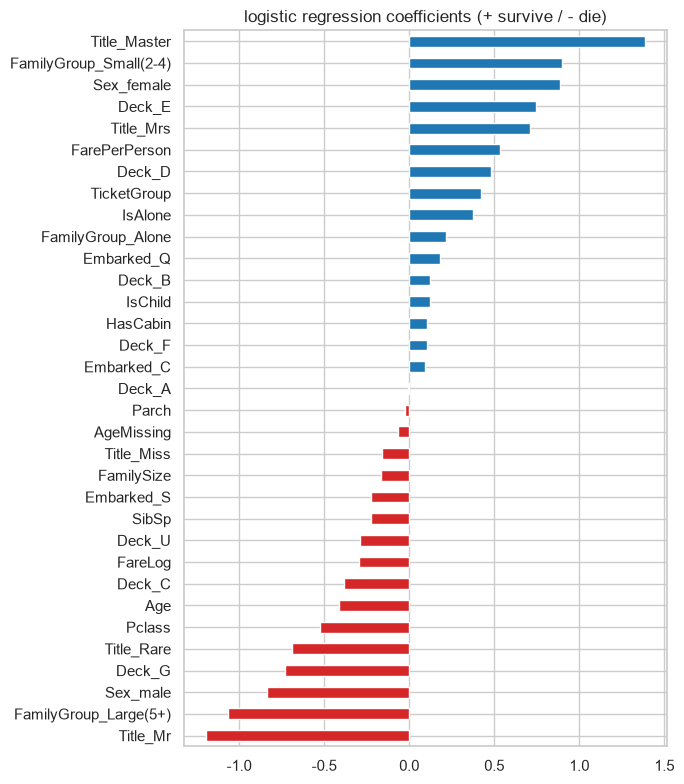

,계수
Title_Mr,-1.194
FamilyGroup_Large(5+),-1.064
Sex_male,-0.836
Deck_G,-0.730
Title_Rare,-0.691
Title_Mrs,0.709
Deck_E,0.746
Sex_female,0.885
FamilyGroup_Small(2-4),0.899
Title_Master,1.385


In [35]:
log_pipe = make_pipe(LogisticRegression(max_iter=2000)).fit(train[FEATURES_ALL], y)
names = log_pipe.named_steps['prep'].get_feature_names_out()
coef = pd.Series(log_pipe.named_steps['model'].coef_[0], index=[n.split('__')[1] for n in names]).sort_values()
plt.figure(figsize=(7, 8))
coef.plot.barh(color=np.where(coef > 0, 'tab:blue', 'tab:red'))
plt.title('logistic regression coefficients (+ survive / - die)'); plt.tight_layout(); plt.show()
display(pd.concat([coef.head(5), coef.tail(5)]).round(3).to_frame('계수'))

**읽기** — 사망 쪽으로 가장 강하게 미는 것은 호칭 `Mr`(−1.19), 대가족(−1.06), 남성(−0.84)입니다.
생존 쪽은 호칭 `Master`(+1.39, 남자아이), 소가족(+0.90), 여성(+0.89), `Mrs`(+0.71)입니다.
EDA에서 본 "여성·어린이 먼저", "소가족 유리, 대가족 불리"와 방향이 같습니다.

서로 겹치는 특성(Sex와 Title, Pclass와 FareLog)이 함께 있으면 계수가 나눠 가져서 하나만 보고 해석하기 어렵습니다.
계수는 **방향** 정도로만 읽습니다.

## 13-2 랜덤 포레스트 중요도

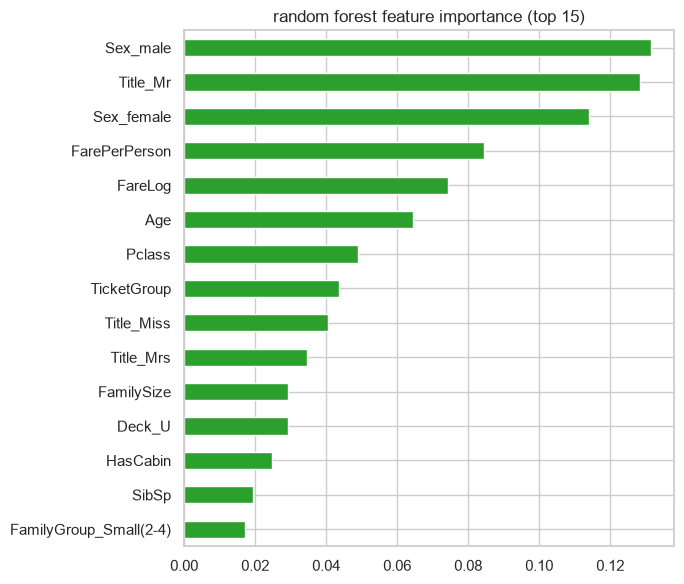

In [36]:
rf_pipe = make_pipe(RandomForestClassifier(n_estimators=300, max_depth=7, random_state=SEED)).fit(train[FEATURES_ALL], y)
importance = pd.Series(rf_pipe.named_steps['model'].feature_importances_,
                       index=[n.split('__')[1] for n in rf_pipe.named_steps['prep'].get_feature_names_out()])
importance.sort_values().tail(15).plot.barh(figsize=(7, 6), color='tab:green')
plt.title('random forest feature importance (top 15)'); plt.tight_layout(); plt.show()

성별(`Sex`)과 호칭 `Mr`, 요금 관련 특성, 등급, 나이가 상위에 옵니다. 숲 모델의 중요도는 "얼마나 자주, 얼마나 유용하게
질문에 쓰였나"이며, 값의 종류가 많은 숫자 특성(나이·요금)이 높게 나오는 경향이 있다는 점은 감안합니다.

## 13-3 오답 분석 — 모델은 누구를 틀리나

교차검증 예측(각 승객이 자신을 학습에 쓰지 않은 모델에게 받은 예측)으로 오답을 분석합니다.

In [37]:
oof = cross_val_predict(make_pipe(LogisticRegression(max_iter=2000)), train[FEATURES_ALL], y,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
print(f'교차검증 예측 정확도: {accuracy_score(y, oof):.4f}')
cm = confusion_matrix(y, oof)
display(pd.DataFrame(cm, index=['실제 사망', '실제 생존'], columns=['예측 사망', '예측 생존']))

analysis = train.assign(pred=oof, wrong=(oof != y).astype(int))
error_table = analysis.groupby(['Sex', 'Pclass']).agg(인원=('wrong', 'size'), 실제생존률=('Survived', 'mean'),
                                                     예측생존률=('pred', 'mean'), 오답률=('wrong', 'mean'))
display(error_table.round(3))

교차검증 예측 정확도: 0.8260


,예측 사망,예측 생존
실제 사망,474,75
실제 생존,80,262


인원  실제생존률  예측생존률    오답률
Sex    Pclass                          
female 1        94  0.968  0.979  0.053
       2        76  0.921  0.974  0.105
       3       144  0.500  0.812  0.354
male   1       122  0.369  0.287  0.377
       2       108  0.157  0.083  0.074
       3       347  0.135  0.029  0.107

**읽기**
- 혼동행렬: 실제 생존자를 사망으로 예측한 경우(놓침)와 사망자를 생존으로 예측한 경우를 셉니다.
- **오답률이 가장 높은 곳은 5-3에서 예상한 "애매한 그룹"** 입니다.
  - **3등석 여성 (오답률 35%)**: 실제 생존률은 50%인데 모델은 81%를 생존으로 예측합니다. "여성이면 생존" 쪽으로 기울어 있습니다.
  - **1등석 남성 (오답률 38%)**: 실제 생존률 37%인데 모델은 29%만 생존으로 예측합니다.
- 2등석 남성처럼 거의 다 사망한 그룹은 "사망"으로 찍으면 대부분 맞습니다.

> 정확도를 더 올리려면 **이 애매한 그룹 안에서 생존자와 사망자를 가르는 정보**가 필요합니다.
> 예: 3등석 여성 중 대가족(FamilySize 5+)은 대부분 사망 → 가족 규모와 성별·등급을 함께 보는 특성.

In [38]:
third_female = analysis[(analysis['Sex'] == 'female') & (analysis['Pclass'] == 3)]
display(third_female.groupby('FamilyGroup').agg(인원=('Survived', 'size'), 생존률=('Survived', 'mean'),
                                               오답률=('wrong', 'mean')).round(3))

,인원,생존률,오답률
FamilyGroup,,,
Alone,60,0.617,0.383
Large(5+),27,0.111,0.111
Small(2-4),57,0.561,0.439


3등석 여성 중 **대가족은 생존률 11%** 로 낮고, 모델도 이것은 잘 맞힙니다(오답률 11%).
어려운 것은 **혼자(생존률 62%)·소가족(56%)** 인 3등석 여성입니다. 생존과 사망이 반반에 가까워 오답률이 38~44%입니다.
이 그룹 안에서 생존자와 사망자를 가르는 정보를 찾는 것이 다음 개선 방향입니다(15장 다음 단계).

---
# 14. 하이퍼파라미터 조정과 최종 제출

## 14-1 랜덤 포레스트 조정

나무의 깊이(`max_depth`)와 잎의 최소 인원(`min_samples_leaf`)을 바꿔 봅니다. 깊고 잎이 작을수록 학습 데이터를 외우기 쉽습니다.

In [39]:
grid = GridSearchCV(make_pipe(RandomForestClassifier(n_estimators=300, random_state=SEED)),
                    param_grid={'model__max_depth': [4, 6, 8, None], 'model__min_samples_leaf': [1, 3, 5]},
                    cv=cv, scoring='accuracy', return_train_score=True, n_jobs=-1)
grid.fit(train[FEATURES_ALL], y)
tuning = pd.DataFrame(grid.cv_results_)[['param_model__max_depth', 'param_model__min_samples_leaf',
                                         'mean_train_score', 'mean_test_score', 'std_test_score']]
tuning.columns = ['max_depth', 'min_samples_leaf', '학습 정확도', '검증 정확도', '검증 표준편차']
tuning['과적합 차이'] = tuning['학습 정확도'] - tuning['검증 정확도']
display(tuning.sort_values('검증 정확도', ascending=False).round(4))
print('가장 좋은 설정:', grid.best_params_, '| 검증 정확도', round(grid.best_score_, 4))

,max_depth,min_samples_leaf,학습 정확도,검증 정확도,검증 표준편차,과적합 차이
5,6,5,0.8530,0.8316,0.0194,0.0213
4,6,3,0.8597,0.8316,0.0175,0.0281
3,6,1,0.8763,0.8309,0.0181,0.0454
2,4,5,0.8360,0.8309,0.0187,0.0052
8,8,5,0.8643,0.8305,0.0163,0.0338
1,4,3,0.8362,0.8305,0.0189,0.0057
0,4,1,0.8375,0.8305,0.0191,0.0070
11,None,5,0.8666,0.8301,0.0157,0.0365
10,None,3,0.8895,0.8301,0.0180,0.0593
7,8,3,0.8804,0.8290,0.0152,0.0514


가장 좋은 설정: {'model__max_depth': 6, 'model__min_samples_leaf': 5} | 검증 정확도 0.8316


깊이 제한이 없고(None) 잎이 1명인 설정은 학습 정확도가 매우 높지만 검증 정확도는 높지 않습니다 → 과적합.
상위 설정들은 서로 차이가 표준편차보다 훨씬 작습니다. 조정으로 얻는 이득은 크지 않습니다.

## 14-2 최종 모델 선택

**선택 규칙:** 가장 높은 모델과 로지스틱 회귀의 차이가 **흔들림(표준편차)의 절반보다 작으면**, 더 단순하고 해석하기 쉬운
로지스틱 회귀를 고릅니다. 그보다 확실히 크면 더 좋은 모델을 고릅니다.

In [40]:
log_result = evaluate(make_pipe(LogisticRegression(max_iter=2000)), FEATURES_ALL, '로지스틱 회귀')
rf_best = grid.best_estimator_
rf_result = evaluate(rf_best, FEATURES_ALL, '랜덤 포레스트(조정)')
gap = rf_result['검증 정확도 평균'] - log_result['검증 정확도 평균']
noise = log_result['검증 표준편차']
print(f"로지스틱 {log_result['검증 정확도 평균']:.4f} | 조정된 숲 {rf_result['검증 정확도 평균']:.4f} | "
      f"차이 {gap:+.4f} | 흔들림(표준편차) {noise:.4f}")

if gap > noise / 2:
    final_name, final_model = '랜덤 포레스트(조정)', rf_best
else:
    final_name, final_model = '로지스틱 회귀', make_pipe(LogisticRegression(max_iter=2000))
print('최종 선택:', final_name)

로지스틱 0.8245 | 조정된 숲 0.8316 | 차이 +0.0071 | 흔들림(표준편차) 0.0221
최종 선택: 로지스틱 회귀


## 14-3 전체 train으로 학습 → test 예측 → 제출 파일

Kaggle 제출 형식은 `PassengerId,Survived` 두 열, 418행, `Survived`는 **정수 0/1**입니다.
파일을 저장한 뒤 **다시 읽어서** 형식을 검사합니다(원본은 예측값을 표로만 출력하고 저장하지 않았음).

In [41]:
final_model.fit(train[FEATURES_ALL], y)
test_pred = final_model.predict(test[FEATURES_ALL]).astype(int)

submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': test_pred})
SUBMISSION_PATH = Path('submission_titanic_claude.csv')
submission.to_csv(SUBMISSION_PATH, index=False)

check = pd.read_csv(SUBMISSION_PATH)
assert list(check.columns) == ['PassengerId', 'Survived'], '열 이름이 다릅니다'
assert len(check) == 418 and check['PassengerId'].is_unique, '행 수 또는 PassengerId 오류'
assert set(check['Survived'].unique()) <= {0, 1}, 'Survived는 0/1이어야 합니다'
assert (check['PassengerId'].values == raw_test['PassengerId'].values).all()
print(f'저장 완료: {SUBMISSION_PATH.resolve()} ({len(check)}행) — 형식 검사 통과')
print(f"test 예측 생존 비율 {check['Survived'].mean():.3f} | train 실제 생존 비율 {y.mean():.3f}")
print(f"test 여성 중 생존 예측 비율 {check['Survived'][test['Sex'] == 'female'].mean():.3f} | "
      f"남성 {check['Survived'][test['Sex'] == 'male'].mean():.3f}")
display(check.head())

저장 완료: G:\내 드라이브\강의자료\국방\2026 국방경진대회 준비\submission_titanic_claude.csv (418행) — 형식 검사 통과
test 예측 생존 비율 0.407 | train 실제 생존 비율 0.384
test 여성 중 생존 예측 비율 0.947 | 남성 0.098


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


마지막 두 줄은 **상식 점검**입니다. test에서 예측한 생존 비율이 train의 생존 비율(38%)과 너무 다르거나,
여성·남성 예측 비율이 EDA 결과와 크게 다르면 어딘가 실수가 있다는 신호입니다.

> Kaggle에 제출하면 **공개 점수는 보통 교차검증 점수보다 몇 %p 낮게** 나옵니다. test가 418명뿐이라
> 점수 자체도 흔들리고, train과 test의 승객 구성이 조금 다르기 때문입니다. 교차검증 평균을 더 믿을 만한 추정치로 봅니다.

---
# 15. 정리

## 발견 요약

| 질문 | 답 | 근거 |
|---|---|---|
| 가장 강한 단서는? | **성별** | 여성 74% vs 남성 19%, 성별 규칙만으로 78.7% |
| 등급의 효과는? | 1등석 63% → 3등석 24% | 같은 성별 안에서도 등급이 높을수록 생존 |
| "어린이 먼저"는 사실? | 그렇다 | 0~16세 55%, 호칭 Master(남자아이) 58% vs Mr 16% |
| 가족은? | 소가족(2~4명) 유리, 혼자·대가족 불리 | 30% / 58% / 16% |
| 항구는? | 직접 원인보다 **등급 구성 차이** | C 탑승객의 51%가 1등석 |
| 결측은 정보인가? | 그렇다 | 객실 기록 있음 67% vs 없음 30%, 나이 결측 29% vs 41% |
| 모델 성능은? | 교차검증 약 82~83% | 기준선 61.6%, 성별 규칙 78.7% |
| 누구를 틀리나? | 3등석 여성, 1등석 남성 | 실제 생존률이 50% 근처인 애매한 그룹 |

## 원본에서 고친 오류

| 원본 셀 | 문제 | 수정 |
|---|---|---|
| 데이터 경로 | Colab 전용 | 로컬·Colab 모두, 없으면 자동 다운로드 |
| `train['Sex'] == 'Female'` | 대소문자 불일치로 항상 False | 실제 값 `'female'` 사용 |
| 호칭 매핑 → 재추출 | 숫자로 바꾼 뒤 다시 뽑아 순서가 꼬임 | 한 번 추출 후 글자로 정리 |
| 나이 구간 `and` | `ValueError` | `pd.cut` 사용 |
| `Age`를 구간 번호로 덮어쓰기 | 원래 나이 손실, 이후 `TypeError` | 새 열로 만들기 |
| test 나이를 test 중앙값으로 | train과 기준이 다름 | train 호칭별 중앙값 |
| test 요금 결측 → 0 | "공짜"라는 다른 뜻 | train 등급별 중앙값 |
| `kdeplot(shade=True)` | 최신 seaborn에서 동작 안 함 | `fill=True` |
| 대부분의 열 삭제 | 정보 손실 | 원-핫 인코딩으로 사용 |
| `LinearRegression` + 학습 데이터 채점 | 회귀 모델, R², 부풀린 점수 | 분류 모델 + 교차검증 정확도 |
| 제출 파일 없음 | — | Kaggle 형식 저장 + 검사 |

## 다음 단계 아이디어

1. **애매한 그룹 안의 차이 잡기** — 혼자·소가족 3등석 여성, 1등석 남성에서 생존자를 가를 정보 찾기 (13-3)
2. **같은 일행의 생사 공유** — 같은 티켓·같은 성(surname) 일행은 함께 살거나 함께 죽는 경향. 단, 정답을 쓰는 특성이므로 반드시
   교차검증 **학습 부분 안에서만** 계산해야 누수가 없습니다.
3. **모델 여러 개 합치기** — 로지스틱·숲·부스팅의 확률 평균 (차이가 흔들림보다 큰지 꼭 확인)
4. **나이 결측 채우기 고도화** — 호칭뿐 아니라 등급·가족 수까지 고려한 채우기

---
# 부록. pandas 문자열 함수와 정규표현식 (원본 내용 보존·수정)

원본 중간에 있던 문자열 연습을 그대로 옮기고, **최신 pandas(2.0 이상)에서 바뀐 동작**을 반영했습니다.

## A-1 `str.split`과 `expand`

In [42]:
s2 = pd.Series(['a_b_c', 'c_d_e', np.nan, 'f_g_h'], dtype='string')
print(s2.str.split('_'), '\n')
print('두 번째 조각 (get(1) == [1]):'); print(s2.str.split('_').str.get(1), '\n')
print('expand=True → 표로 펼침:'); display(s2.str.split('_', expand=True))
print('n=1 → 처음 한 번만 자름:'); display(s2.str.split('_', expand=True, n=1))
print('rsplit n=1 → 뒤에서 한 번만 자름:'); display(s2.str.rsplit('_', expand=True, n=1))

0    [a, b, c]
1    [c, d, e]
2         <NA>
3    [f, g, h]
dtype: object 

두 번째 조각 (get(1) == [1]):
0       b
1       d
2    <NA>
3       g
dtype: object 

expand=True → 표로 펼침:


,0,1,2
0,a,b,c
1,c,d,e
2,<NA>,<NA>,<NA>
3,f,g,h


n=1 → 처음 한 번만 자름:


,0,1
0,a,b_c
1,c,d_e
2,<NA>,<NA>
3,f,g_h


rsplit n=1 → 뒤에서 한 번만 자름:


,0,1
0,a_b,c
1,c_d,e
2,<NA>,<NA>
3,f_g,h


- `expand=False`(기본): 각 칸에 **리스트**가 들어간 Series
- `expand=True`: 조각마다 **열**이 생긴 DataFrame. 원본 Series가 `string` 형이면 결과 열도 `string` 형입니다.
- `n`: 최대 몇 번 자를지. `rsplit`은 **오른쪽 끝에서부터** 자릅니다.

## A-2 `str.replace`와 정규표현식 — ⚠️ pandas 2.0부터 기본값이 바뀌었습니다

| pandas 버전 | `str.replace(pat, repl)`의 기본 동작 |
|---|---|
| 1.x (원본 작성 당시) | `pat`을 **정규표현식**으로 해석 (한 글자짜리 `$` 등은 예외로 글자 그대로) |
| **2.0 이상** | `pat`을 **글자 그대로** 해석 (`regex=False`) |

그래서 원본의 결과와 지금 실행 결과가 다를 수 있습니다. **항상 `regex=True` 또는 `regex=False`를 명시**하는 것이 안전합니다.

In [43]:
s3 = pd.Series(['A', 'B', 'C', 'Aaba', 'Baca', '', np.nan, 'CABA', 'dog', 'cat'], dtype='string')
compare = pd.DataFrame({
    '원래 값': s3,
    "'^.a|dog' 정규식": s3.str.replace('^.a|dog', 'XX-XX', case=False, regex=True),
    "'^a|dog' 정규식": s3.str.replace('^a|dog', 'XX-XX', case=False, regex=True),
    "'^.a|dog' 글자 그대로": s3.str.replace('^.a|dog', 'XX-XX', regex=False),
})
display(compare)

,원래 값,'^.a|dog' 정규식,'^a|dog' 정규식,'^.a|dog' 글자 그대로
0,A,A,XX-XX,A
1,B,B,B,B
2,C,C,C,C
3,Aaba,XX-XXba,XX-XXaba,Aaba
4,Baca,XX-XXca,Baca,Baca
5,,,,
6,<NA>,<NA>,<NA>,<NA>
7,CABA,XX-XXBA,CABA,CABA
8,dog,XX-XX,XX-XX,dog
9,cat,XX-XXt,cat,cat


📐 **정규식 `'^.a|dog'` 해석**: `^`(문자열 맨 앞) + `.`(아무 글자 하나) + `a` **또는**(`|`) `dog`.
`case=False`는 대소문자를 구분하지 않습니다(정규식 모드에서만 사용 가능).
→ 'Aaba'의 앞 'Aa', 'Baca'의 앞 'Ba', 'CABA'의 앞 'CA', 'cat'의 앞 'ca', 'dog' 전체가 바뀝니다.
글자 그대로 모드에서는 `'^.a|dog'`라는 문자열이 없으므로 아무것도 바뀌지 않습니다.

## A-3 `$` 같은 특수문자 다루기

In [44]:
dollars = pd.Series(['12', '-$10', '$10,000'], dtype='string')
table = pd.DataFrame({
    '원래 값': dollars,
    "'$' 글자 그대로 → ''": dollars.str.replace('$', '', regex=False),
    "'-$' 글자 그대로 → '-'": dollars.str.replace('-$', '-', regex=False),
    "'-$' 정규식 → '-'": dollars.str.replace('-$', '-', regex=True),
    "r'-\\$' 정규식 → '-'": dollars.str.replace(r'-\$', '-', regex=True),
})
display(table)

,원래 값,'$' 글자 그대로 → '','-$' 글자 그대로 → '-','-$' 정규식 → '-',r'-\$' 정규식 → '-'
0,12,12,12,12,12
1,-$10,-10,-10,-$10,-10
2,"$10,000","10,000","$10,000","$10,000","$10,000"


**읽기**
- 정규식에서 `$`는 "문자열의 끝"이라는 **특수 의미**입니다. 그래서 정규식 `'-$'`는 "끝에 있는 `-`"를 찾아 아무것도 못 바꿉니다.
- 정규식에서 `$` 글자 자체를 찾으려면 `\$`처럼 **역슬래시로 탈출**시키고, 파이썬 문자열 앞에 `r`을 붙입니다: `r'-\$'`.
- 글자 그대로 바꾸고 싶다면 **`regex=False`** 를 쓰면 탈출이 필요 없습니다.

> 7장의 `r' ([A-Za-z]+)\.'`에서 `\.`이 바로 이 "탈출"입니다. `.`은 정규식에서 "아무 글자"라서, 마침표 자체를 찾으려면 `\.`로 씁니다.